# SnowPredict - Milestone 3: EDA, Initial Modeling, and Pipeline Development

**Project group #8**
**Group members:** Livia Jonnatan, Jiwon Kim, Jihoon Park

**Project question (revised proposal):** For any date in the ski season (December 1 to April 30), how well can a model trained on earlier winter seasons predict a weather-based ski-condition index 7 days ahead at seven Canadian ski resorts? 

**Data source:** [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api). Free, no API key.

**Without network:** To run this notebook without any network, unzip the raw data from [Google Drive](https://drive.google.com/file/d/1Uiq8u6BNzvv_2aBrz4tDBLN_AQpXyeE3/view?usp=share_link) into `/data/raw/` and run the notebook.

<div class="alert alert-info" style="color: #4a4a4a; background-color: #fffad2; border-color: #ffedbb; border-width: 1px; border-radius: 3px; padding: 10px;">

**Notebook order follows:**
1. Load the cleaned data and build the index
2. EDA and plots
3. Build the table --> features known on day t, targets on t+7
4. Reference points: historical average and persistence
5. Pipeline
6. Initial model and results
7. Plan for Milestone 4

*Input:* `data/weather_daily_wide.csv` from Milestone 2 (one row = resort, elevation point, calendar day)

*Conventions:* test seasons 2024-2026 are never touched in this notebook. Every model result is cached under `data/results/`, so re-running does not refit.

In [126]:
import warnings

import os, json, time, glob, datetime
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib import cm, colors
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.decomposition import PCA
from sklearn.preprocessing import PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*penalty is deprecated.*")

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11

In [127]:
SEED = 2026
HORIZON = 7
RESULTS = "data/results"
os.makedirs(RESULTS, exist_ok=True)

In [128]:
def cached(name, compute):
    f = f"{RESULTS}/{name}.csv"
    if os.path.isfile(f):
        return pd.read_csv(f, index_col=0)
    out = compute()
    out.to_csv(f)
    return out

# 1. Load the cleaned data and build the index

The daily-wide table keeps every calendar day, so lagged features for early December can use November. Season identifiers and the index are the same definitions as MS2.

**Why these splits:** seasons (not rows) are the unit of splitting because adjacent days within a winter are near copies of each other. Training seasons 2006-2020, validation 2021-2023, and test 2024-2026 as per the proposal (MS2). The test seasons are the most recent winters because this is how forecasts are usually judged. Validation and training (development seasons) will be used for any cross-validation.

In [129]:
RESORTS = ["Whistler Blackcomb", "Big White", "Sun Peaks", "Revelstoke",
           "Lake Louise", "Mont Tremblant", "Mont Sainte-Anne"]
REGION = {"Whistler Blackcomb": "west", "Big White": "west", "Sun Peaks": "west", 
          "Revelstoke": "west", "Lake Louise": "west", "Mont Tremblant": "east", "Mont Sainte-Anne": "east"}
POINTS = ["base", "mid", "high"]

In [130]:
TRAIN_SEASONS = list(range(2006, 2021))
VAL_SEASONS = [2021, 2022, 2023]
TEST_SEASONS = [2024, 2025, 2026]
DEV_SEASONS = TRAIN_SEASONS + VAL_SEASONS
assert max(TRAIN_SEASONS) < min(VAL_SEASONS) < min(TEST_SEASONS)

In [131]:
raw = pd.read_csv("data/weather_daily_wide.csv", parse_dates=["date"])
raw = raw.sort_values(["resort", "point", "date"]).reset_index(drop=True)
raw["season"] = np.where(raw["date"].dt.month >= 7, raw["date"].dt.year + 1, raw["date"].dt.year)
raw["day_of_season"] = (raw["date"] - pd.to_datetime((raw["season"] - 1).astype(str) + "-12-01")).dt.days
raw["month"] = raw["date"].dt.month
print("Daily-wide table:", raw.shape, "| missing values:", int(raw.isna().sum().sum()))

Daily-wide table: (164241, 100) | missing values: 0


In [132]:
# As per MS 2
# Weights are adapted from the skier-preference survey literature (see proposal)
# Sensitivity to the weights will be checked later

def ski_index(df, w_depth=0.30, w_fresh=0.15, w_sun=0.10, w_temp=0.20, w_wind=0.10, w_rain=0.15):
    depth = (df["snow_depth_mean_am"] / 100).clip(0, 1)
    fresh = (df["snowfall_sum_night"] / 15).clip(0, 1)
    sun = (df["sunshine_hours"] / df["daylight_hours"]).clip(0, 1)
    day_t = (df["temp_mean_am"] + df["temp_mean_pm"]) / 2
    temp = 1 - ((day_t + 4).abs().clip(0, 16) / 16)
    wind = 1 - ((df["gust_max_am"].combine(df["gust_max_pm"], max) - 50).clip(0, 50) / 50)
    rain = 1 - ((df["rain_sum_am"] + df["rain_sum_pm"]).clip(0, 5) / 5)
    return 100 * (w_depth * depth + w_fresh * fresh + w_sun * sun + w_temp * temp + w_wind * wind + w_rain * rain)

In [133]:
def index_components(df):
    return pd.DataFrame({
        "depth": (df["snow_depth_mean_am"] / 100).clip(0, 1),
        "fresh": (df["snowfall_sum_night"] / 15).clip(0, 1),
        "sun": (df["sunshine_hours"] / df["daylight_hours"]).clip(0, 1),
        "temp": 1 - (((df["temp_mean_am"] + df["temp_mean_pm"]) / 2+4).abs().clip(0, 16) / 16),
        "wind": 1 - ((df["gust_max_am"].combine(df["gust_max_pm"], max) - 50).clip(0, 50) / 50),
        "rain": 1 - ((df["rain_sum_am"] + df["rain_sum_pm"]).clip(0, 5) / 5),
    }, index=df.index)

In [134]:
WEIGHTS = {"depth": 0.30, "fresh": 0.15, "sun": 0.10, "temp":0.20, "wind":0.10, "rain":0.15}

raw["ski_index"] = ski_index(raw)

In [135]:
def in_ski_window(dates):
    m = dates.dt.month
    return (m == 12) | (m <= 4)

In [136]:
ski = raw[in_ski_window(raw["date"]) & raw["season"].between(2006, 2026)].copy()
ski["split"] = np.select([ski["season"].isin(TRAIN_SEASONS), ski["season"].isin(VAL_SEASONS), ski["season"].isin(TEST_SEASONS)], ["train", "val", "test"], default="unused")

# mid-mountain is the prediction point
# at MS2 we found the 3 points differ mostly in temperature (we can adjust later)
mid = ski[ski["point"] == "mid"].copy()
print("Ski-season table:", ski.shape, "| mid point only:", mid.shape)
ski.groupby("split")["season"].agg(n_rows="size", seasons="nunique")

Ski-season table: (66696, 102) | mid point only: (22232, 102)


,n_rows,seasons
split,,
test,9534,3
train,47649,15
val,9513,3


# 2. Exploratory Data Analysis

The question fixes the target (the index 7 days ahead) and the comparison (historical day-of-season average). So the EDA asks four things: what the target looks like, how much of it the calendar alone explains, how much of it today's state explains, and which variables at day t relate to the target at t+7.

Morning snow depth is tracked along with the index, because it is the index's largest term and in units that are easy to explain and understand.

All EDA uses the **mid** point in the development seasons (2006-2023) only.

## 2.1 What does the target look like?

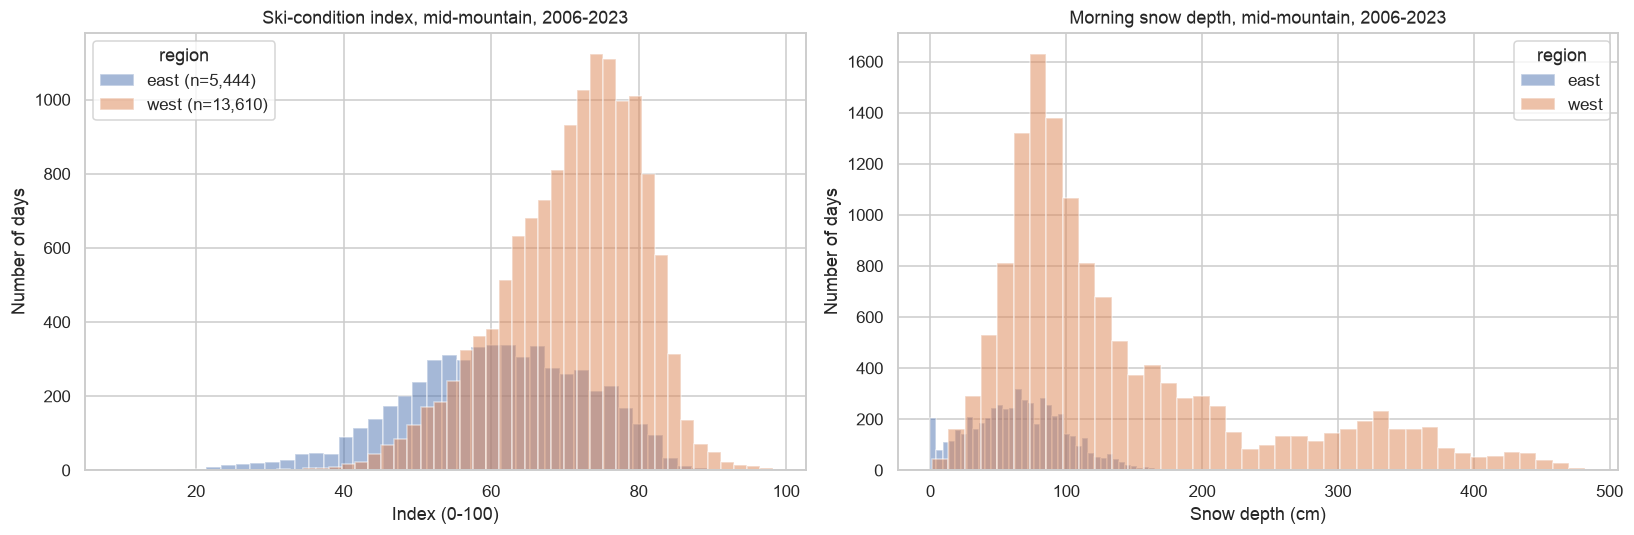

ski_index                   snow_depth_mean_am                   
                        mean   std   min   max               mean   std   min    max
resort                                                                              
Big White               68.0   9.7  30.0  90.8               77.0  25.3   1.2  140.8
Lake Louise             70.5   8.3  40.9  90.9              100.7  23.1  26.2  158.8
Mont Sainte-Anne        64.5  11.3  18.5  89.3               79.3  34.4   0.0  179.0
Mont Tremblant          56.5  11.8   9.4  88.7               51.0  27.9   0.0  132.0
Revelstoke              74.7   7.0  47.1  92.4              158.5  36.9  54.5  235.0
Sun Peaks               64.9   9.2  27.4  85.3               65.8  20.6   4.0  120.0
Whistler Blackcomb      77.2   6.9  48.3  98.2              305.4  82.0  75.0  482.2

In [137]:
dev = mid[mid["season"].isin(DEV_SEASONS)]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for region, g in dev.groupby("region"):
    axes[0].hist(g["ski_index"], bins=40, alpha=0.5, label=f"{region} (n={len(g):,})")
    axes[1].hist(g["snow_depth_mean_am"], bins=40, alpha=0.5, label=region)
axes[0].set_title("Ski-condition index, mid-mountain, 2006-2023")
axes[0].set_xlabel("Index (0-100)")
axes[0].set_ylabel("Number of days")
axes[0].legend(title="region")
axes[1].set_title("Morning snow depth, mid-mountain, 2006-2023")
axes[1].set_xlabel("Snow depth (cm)")
axes[1].set_ylabel("Number of days")
axes[1].legend(title="region")
fig.tight_layout()
plt.show()

dev.groupby("resort")[["ski_index", "snow_depth_mean_am"]].agg(["mean", "std", "min", "max"]).round(1)

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** Average ski-index scores ranged from 56.5 at Mont Tremblant to 77.2 at Whistler Blackcomb. This variation supports comparing forecasts against a separate historical baseline for each resort.

## 2.2 How much does the calendar alone explain?

The historical day-of-season average is our **baseline**. If the index follows a tight seasonal curve, the baseline is hard to beat. If the spread around the curve is wide, there is room for a model.

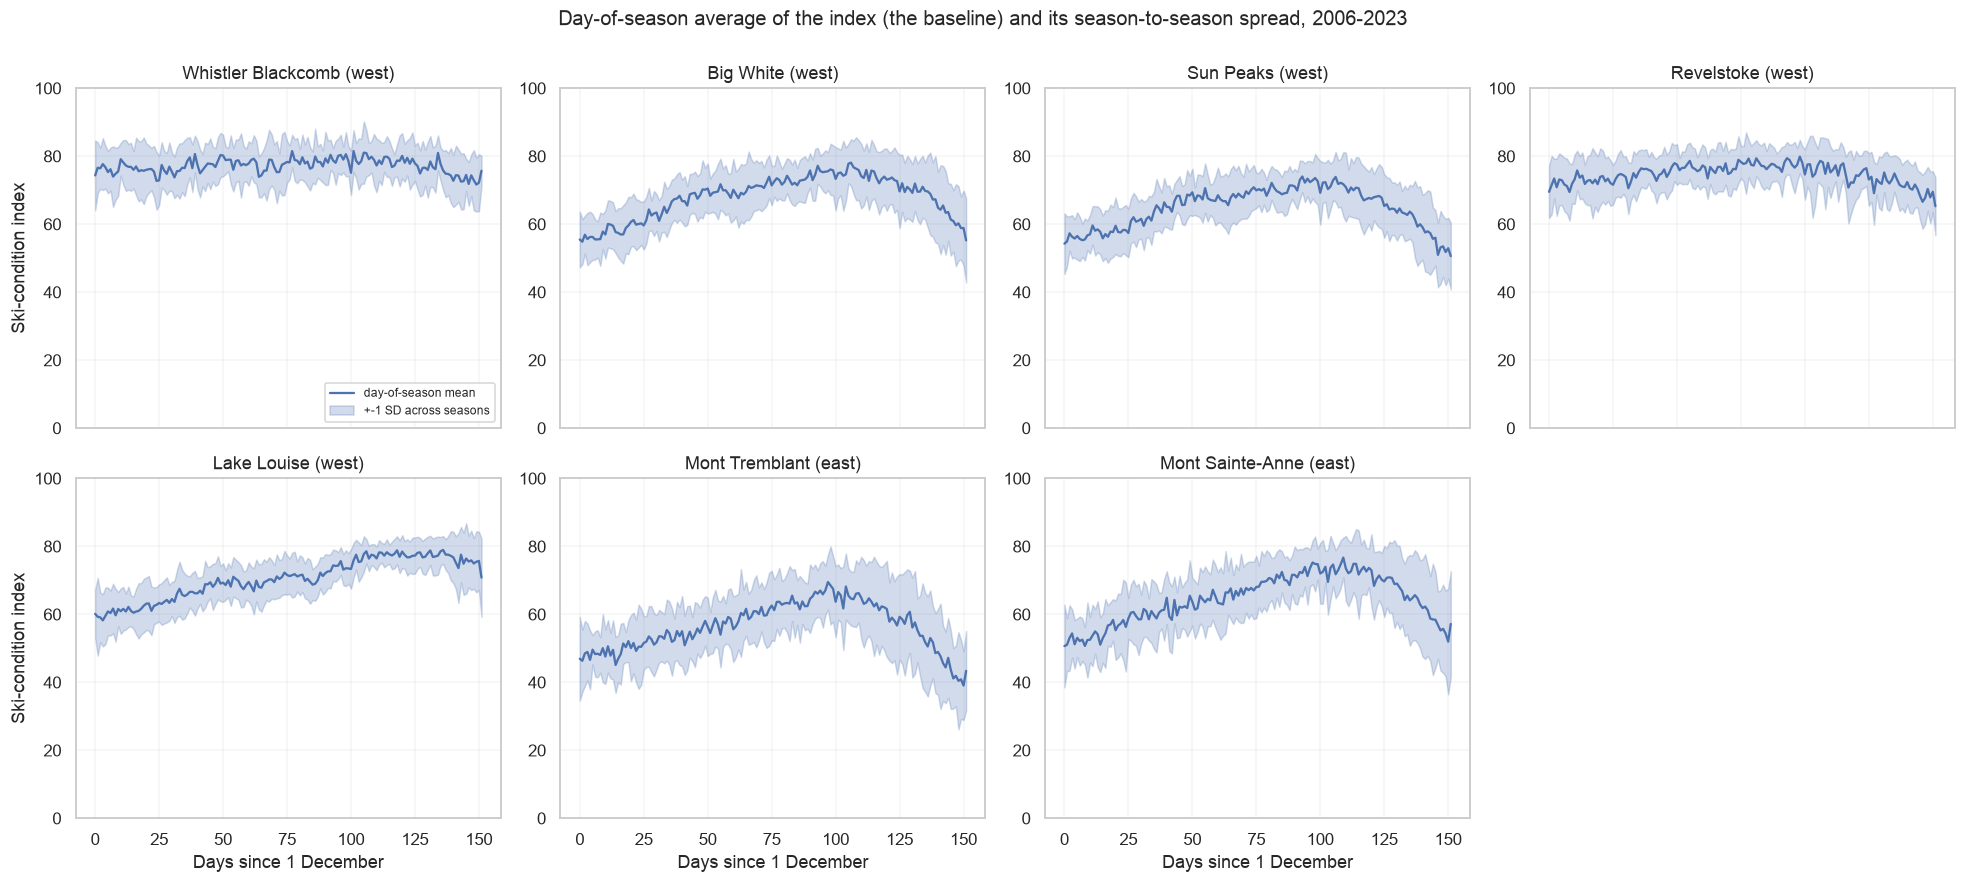

In [176]:
clim_curve = dev.groupby(["resort", "day_of_season"]).agg(idx_mean=("ski_index", "mean"), idx_sd=("ski_index", "std"), 
                                                          sd_mean=("snow_depth_mean_am", "mean"), sd_sd=("snow_depth_mean_am", "std")).reset_index()
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
for ax, name in zip(axes.flat, RESORTS):
    c = clim_curve[clim_curve["resort"] == name]
    ax.plot(c["day_of_season"], c["idx_mean"], color="C0", label="day-of-season mean")
    ax.fill_between(c["day_of_season"], c["idx_mean"] - c["idx_sd"], c["idx_mean"] + c["idx_sd"], color="C0", alpha=0.25, label="+-1 SD across seasons")
    ax.set_title(f"{name} ({REGION[name]})")
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.2)
for ax in axes[1, :3]:
    ax.set_xlabel("Days since 1 December")
for ax in axes[:, 0]:
    ax.set_ylabel("Ski-condition index")
axes.flat[-1].set_visible(False)
axes.flat[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Day-of-season average of the index (the baseline) and its season-to-season spread, 2006-2023", y=1)
fig.tight_layout()
plt.show()

In [139]:
def calendar_r2(df, col):
    fitted = df.groupby(["resort", "day_of_season"])[col].transform("mean")
    return 1 - ((df[col] - fitted) ** 2).sum() / ((df[col] - df[col].mean()) ** 2).sum()

In [140]:
pd.DataFrame({
    "calendar R2 (pooled)": {"ski_index": calendar_r2(dev, "ski_index"), "snow_depth_mean_am": calendar_r2(dev, "snow_depth_mean_am")},
    "mean SD around the curve": {"ski_index": clim_curve["idx_sd"].mean(), "snow_depth_mean_am": clim_curve["sd_sd"].mean()},
}).round(2)

,calendar R2 (pooled),mean SD around the curve
ski_index,0.56,7.44
snow_depth_mean_am,0.90,26.27


<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** Resort-specific day-of-season averages explain 56% of the pooled variation in the ski index and 90% in morning snow depth in the development data. The ski index shows more variation beyond the seasonal pattern.

## 2.3 Which terms carry the index?

The index is a weighted sum of six 0-1 terms. If one term dominates its variance, predicting that term well matters most.

In [141]:
comp = index_components(dev)
weighted = comp.mul(pd.Series(WEIGHTS)) * 100
share_mean = weighted.groupby(dev["resort"]).mean().reindex(RESORTS)

var_share = pd.Series({c: np.cov(weighted[c], dev["ski_index"]) [0, 1] / dev["ski_index"].var() for c in weighted.columns})

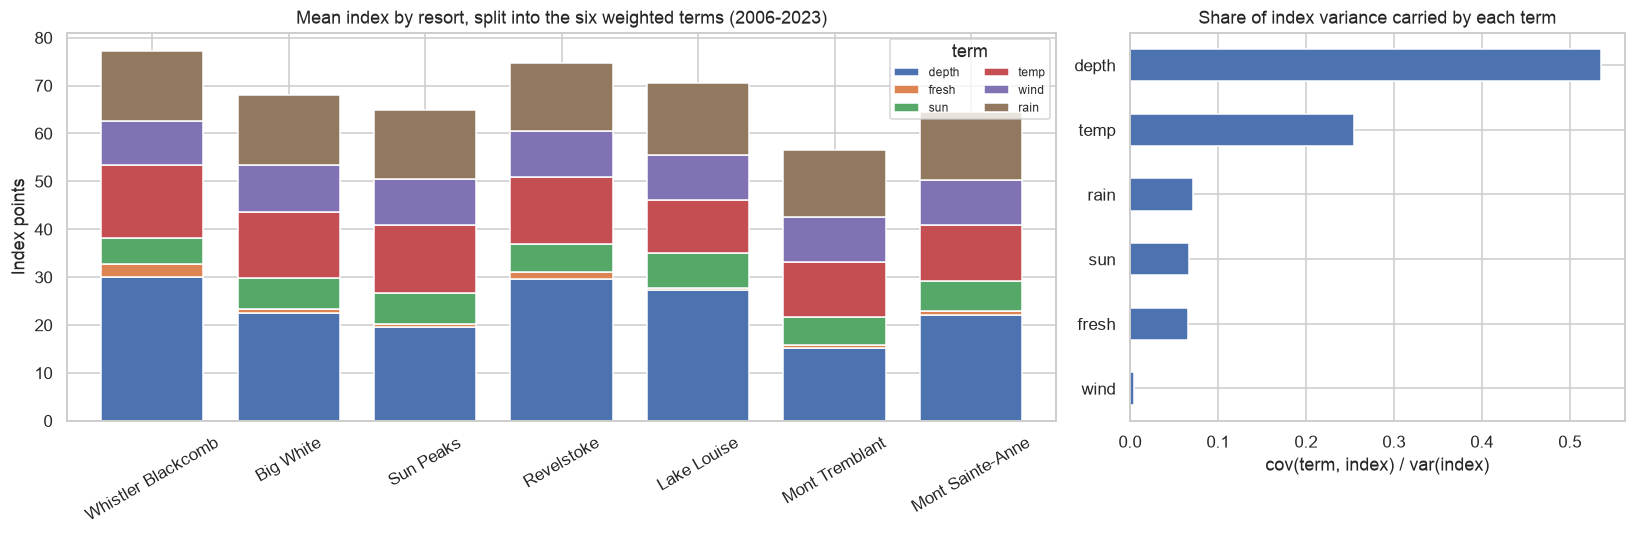

depth    0.536
temp     0.254
rain     0.072
sun      0.067
fresh    0.066
wind     0.005
dtype: float64

In [142]:
fig, axes = plt.subplots(1, 2, figsize=(15,5), gridspec_kw={"width_ratios": [2,1]})
share_mean.plot.bar(stacked=True, ax=axes[0], width=0.75)
axes[0].set_title("Mean index by resort, split into the six weighted terms (2006-2023)")
axes[0].set_ylabel("Index points")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="term", fontsize=8, ncol=2)
var_share.sort_values().plot.barh(ax=axes[1], color="C0")
axes[1].set_title("Share of index variance carried by each term")
axes[1].set_xlabel("cov(term, index) / var(index)")
fig.tight_layout()
plt.show()
var_share.round(3).sort_values(ascending=False)

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** Snow depth contributed the largest share of index variance (53.6%), followed by temperature (25.4%). This supports tracking snow depth alongside the index.

## 2.4 How much does today's state explain?

Persistence ("the index in 7 days equals the index today") is another baseline, and the lag features in Section 3 are built on the same idea. Autocorrelation on the raw series mixes in the calendar, so we also use the anomaly from the day-of-season mean (MS2).

In [143]:
dev = dev.sort_values(["resort", "date"]).copy()
for col in ["ski_index", "snow_depth_mean_am"]:
    lead = dev.groupby(["resort", "season"])[col].shift(-HORIZON)
    dev[f"{col}_lead{HORIZON}"] = lead
pairs = dev.dropna(subset=[f"ski_index_lead{HORIZON}", f"snow_depth_mean_am_lead{HORIZON}"])

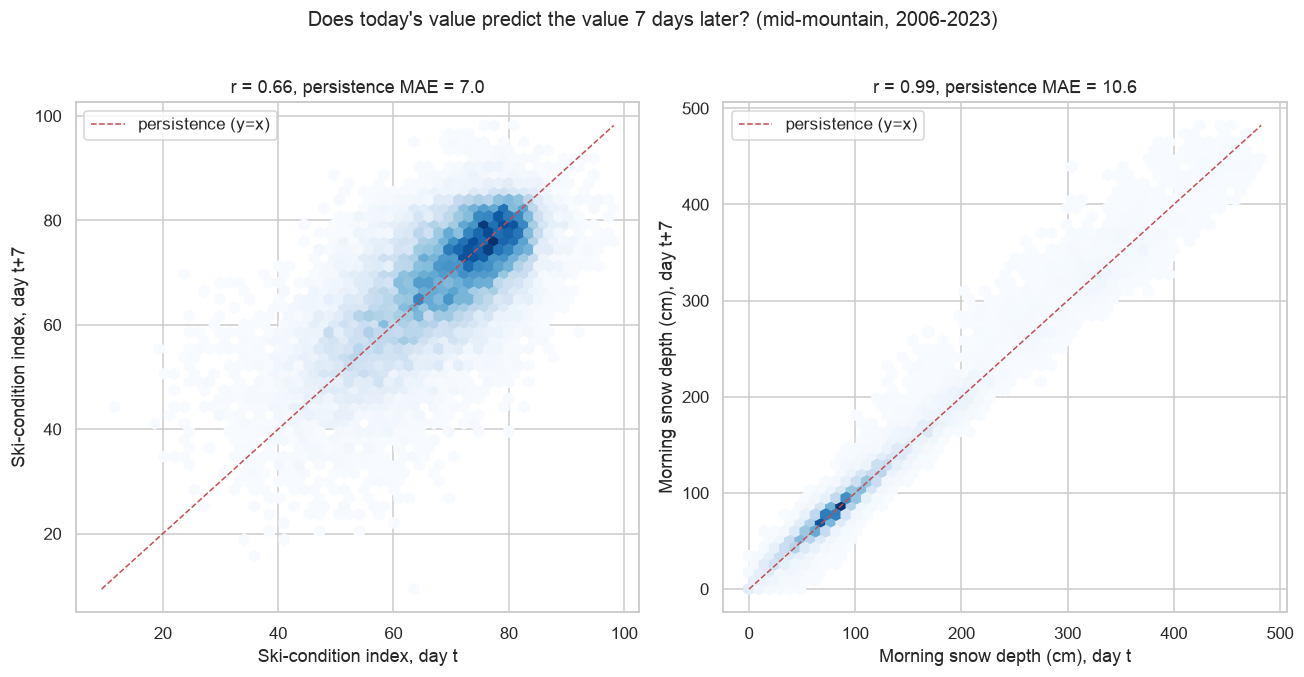

In [144]:
fig, axes = plt.subplots(1, 2, figsize=(12,6))
for ax, col, lab in zip(axes, ["ski_index", "snow_depth_mean_am"], ["Ski-condition index", "Morning snow depth (cm)"]):
    x, y = pairs[col], pairs[f"{col}_lead{HORIZON}"]
    ax.hexbin(x, y, gridsize=50, cmap="Blues", mincnt=1)
    lim = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(lim, lim, "r--", lw=1, label="persistence (y=x)")
    ax.set_xlabel(f"{lab}, day t")
    ax.set_ylabel(f"{lab}, day t+{HORIZON}")
    ax.set_title(f"r = {np.corrcoef(x,y)[0,1]:.2f}, persistence MAE = {np.abs(y-x).mean():.1f}")
    ax.legend(loc="upper left")
fig.suptitle(f"Does today's value predict the value {HORIZON} days later? (mid-mountain, 2006-2023)", y=1.02)
fig.tight_layout()
plt.show()

In [145]:
# Pooled anomaly autocorrelation at lag 7: remove the calendar, keep this winter's level (MS2)
targets_ac = ["snow_depth_mean_am", "ski_index", "temperature_2m_mean", "sunshine_hours", "rain_sum", "wind_gusts_10m_max"]
clim_mean = dev.groupby(["resort", "day_of_season"])[targets_ac].transform("mean")
anom = dev[["resort", "season", "date"]].join(dev[targets_ac] - clim_mean)

In [146]:
def pooled_anomaly_ac(a, col, lag=HORIZON):
    xs, ys = [], []
    for _, g in a.groupby(["resort", "season"]):
        v = g.sort_values("date")[col].to_numpy()
        xs.append(v[:-lag])
        ys.append(v[lag:])
    return np.corrcoef(np.concatenate(xs), np.concatenate(ys))[0,1]

In [147]:
ac = pd.DataFrame([{"resort": r, "variable": t, "ac": pooled_anomaly_ac(anom[anom["resort"] == r], t)} for r in RESORTS for t in targets_ac])
ac.pivot(index="variable", columns="resort", values="ac").reindex(targets_ac).round(2)

resort,Big White,Lake Louise,Mont Sainte-Anne,Mont Tremblant,Revelstoke,Sun Peaks,Whistler Blackcomb
variable,,,,,,,
snow_depth_mean_am,0.91,0.91,0.89,0.87,0.88,0.89,0.89
ski_index,0.45,0.29,0.37,0.40,0.11,0.40,0.07
temperature_2m_mean,0.17,0.17,0.14,0.14,0.16,0.18,0.20
sunshine_hours,0.04,0.03,0.04,0.04,0.01,0.02,0.02
rain_sum,0.04,0.02,0.02,0.02,0.07,0.06,0.05
wind_gusts_10m_max,0.00,0.03,0.07,0.05,0.03,0.22,0.06


<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** After removing the seasonal pattern, seven-day correlations remained high for snow depth (0.87-0.91) but were weaker for the ski index (0.07-0.45). Persistence is therefore a stronger reference for snow depth.

## 2.5 Which variables at day t relate to the target at t+7?

This is a step before feature engineering: the correlation of each daily variable on day t with the two targets on day t+7, within the development seasons.

In [148]:
screen_vars = ["snow_depth_mean_am", "snow_depth_mean_pm", "snowfall_sum", "snowfall_sum_night", "rain_sum", "precipitation_sum", "temperature_2m_mean", "temperature_2m_max", "temperature_2m_min", "temp_min_night",
               "hours_above_0c_pm", "wet_bulb_temperature_2m_mean", "dew_point_2m_mean", "relative_humidity_2m_mean", "sunshine_hours", "cloud_cover_mean", "shortwave_radiation_sum", "wind_speed_10m_max", "wind_gusts_10m_max",
               "surface_pressure_mean", "soil_temperature_0_to_7cm_mean", "day_of_season", "ski_index"]
corr = pd.DataFrame({
    f"index t+{HORIZON}": pairs[screen_vars].corrwith(pairs[f"ski_index_lead{HORIZON}"]),
    f"snow depth t+{HORIZON}": pairs[screen_vars].corrwith(pairs[f"snow_depth_mean_am_lead{HORIZON}"]),
})

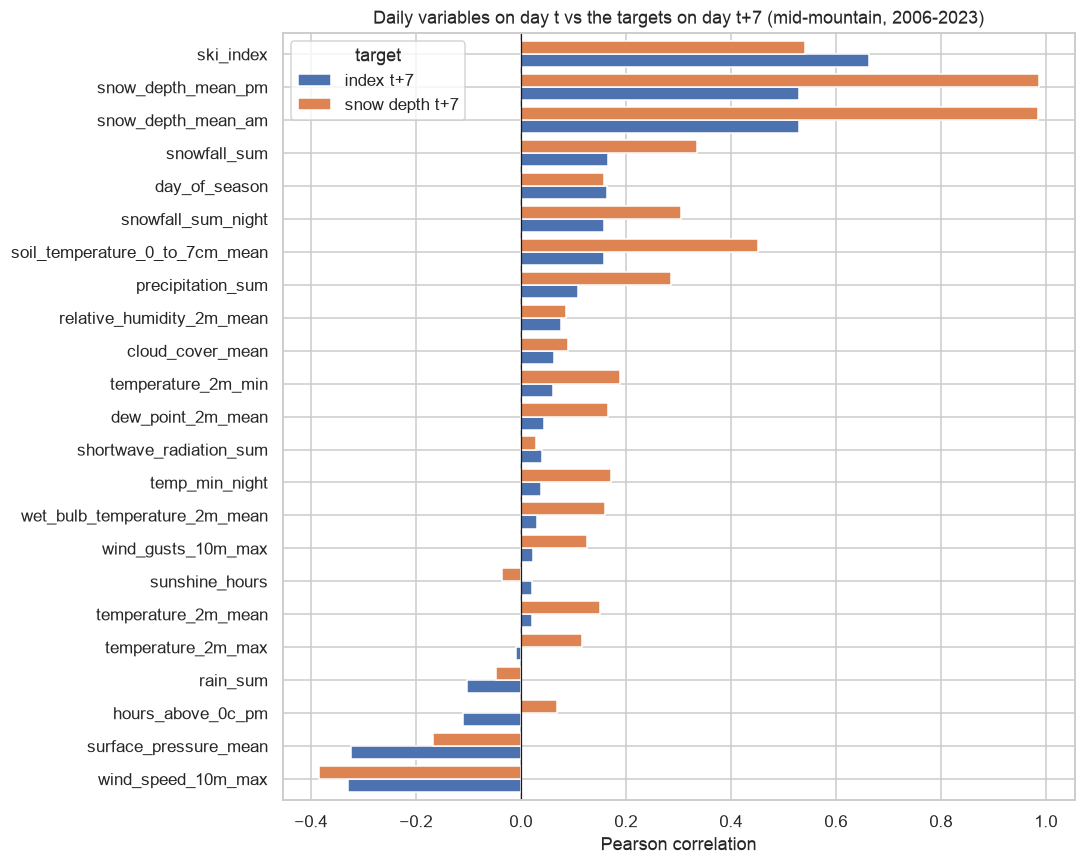

,index t+7,snow depth t+7
ski_index,0.66,0.54
snow_depth_mean_pm,0.53,0.99
snow_depth_mean_am,0.53,0.99
snowfall_sum,0.17,0.34
snowfall_sum_night,0.16,0.31
day_of_season,0.16,0.16
soil_temperature_0_to_7cm_mean,0.16,0.45
precipitation_sum,0.11,0.29
relative_humidity_2m_mean,0.08,0.09
temperature_2m_min,0.06,0.19


In [149]:
fig, ax = plt.subplots(figsize=(10,8))
corr.sort_values(f"index t+{HORIZON}").plot.barh(ax=ax, width=0.8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Pearson correlation")
ax.set_title(f"Daily variables on day t vs the targets on day t+{HORIZON} (mid-mountain, 2006-2023)")
ax.legend(title="target")
fig.tight_layout()
plt.show()
corr.round(2).sort_values(f"index t+{HORIZON}", ascending=False).head(10)

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** Today's ski index had the strongest correlation with the index seven days later (0.66), followed by today's snow depth (0.53). Today's snow depth was also highly correlated with snow depth seven days later (0.99).

# 3. Building the table: features at t, targets at t+7

One row per (resort, prediction date t) on the mid point. Features use rows with date <= t only. Targets are the index and morning snow depth on t+7. The table is built on the full-year series so the November lags exist for early December, then restricted to prediction dates whose target date is also inside the ski season.

Every feature is measured on or before day t. The target is built from the weather on day t+7, which is not in the table.

**Feature choices and why:**
- Current day: every daily and daypart variable for day t. The night before t is over by the time we predict. So overnight snowfall is included.
- Lags 1, 3, 7, 14 days of snow depth, temperature and the index, rolling sums over 3, 7, 14, 30 days of snowfall and rain, and rolling means of temperature, sunshine, and the index. Short windows are used because the memory that exists is short; the 14- and 30-day windows make a slow melt or a long dry spell visible.
- Elevation: base-minus-high mean temperature. This was the thing MS2 found the three points differ on.
- Resort: one indicator per resort plus an east/west flag. So the linear models can shift level by resort.
- Season as a number: so a linear model can follow the warming trend (found in MS2).
- `day_of_season` for the tree models and `sin`/`cos` of day of season for the linear models and kNN. A linear model with only the day count can fit a straight trend, not the bump we saw in 2.2. A sine and cosine pair can fit a bump with any peak date. The period is 365 because the cycle is the calendar year, not the 150-day season.

In [150]:
# day-t variables (daily block + dayparts of day t). The night before t is over by the time we predict.
CURRENT = [
    "snow_depth_mean_am", "snow_depth_mean_pm", "snowfall_sum", "snowfall_sum_night", "rain_sum", "precipitation_sum", "precipitation_hours","temperature_2m_mean", "temperature_2m_max", "temperature_2m_min", 
    "temp_min_night", "temp_mean_am", "temp_mean_pm", "hours_above_0c_pm", "wet_bulb_temperature_2m_mean", "dew_point_2m_mean", "relative_humidity_2m_mean", "sunshine_hours", "daylight_hours", "cloud_cover_mean", 
    "shortwave_radiation_sum", "wind_speed_10m_max", "wind_gusts_10m_max", "gust_max_pm", "surface_pressure_mean", "soil_temperature_0_to_7cm_mean", "ski_index",
]
LAG_VARS = ["snow_depth_mean_am", "temperature_2m_mean", "ski_index"]
LAGS = [1, 3, 7, 14]
ROLL_SUM_VARS = ["snowfall_sum", "rain_sum"]
ROLL_MEAN_VARS = ["temperature_2m_mean", "sunshine_hours", "ski_index"]
WINDOWS = [3, 7, 14, 30]
TARGETS = ["ski_index", "snow_depth_mean_am"]

In [151]:
def days_since(s, thresh=10, cap=60):
    #days since the last day with s >= thresh, capped (uses only past data)
    out, cnt = np.empty(len(s)), cap
    for i, v in enumerate(s.to_numpy()):
        cnt = 0 if v >= thresh else min(cnt+1, cap)
        out[i] = cnt
    return pd.Series(out, index=s.index)

In [152]:
def build_supervised(daily, horizon=HORIZON):
    m = daily[daily["point"] == "mid"].sort_values(["resort", "date"]).copy()
    hi = daily[daily["point"] == "high"][["resort", "date", "temperature_2m_mean"]].rename(columns={"temperature_2m_mean": "temp_high"})
    lo = daily[daily["point"] == "base"][["resort", "date", "temperature_2m_mean"]].rename(columns={"temperature_2m_mean": "temp_base"})
    m = m.merge(hi, on=["resort", "date"], validate="one_to_one").merge(lo, on=["resort", "date"], validate="one_to_one")
    m["temp_base_minus_high"] = m["temp_base"] - m["temp_high"]
    m["sun_frac"] = (m["sunshine_hours"] / m["daylight_hours"]).clip(0, 1)
    m["freeze_thaw"] = ((m["temperature_2m_max"] > 0) & (m["temperature_2m_min"] < 0)).astype(float)
    g = m.groupby("resort", sort=False)

    f = {}
    for v in LAG_VARS:
        for L in LAGS:
            f[f"{v}_lag{L}"] = g[v].shift(L)
    for v in ROLL_SUM_VARS:
        for w in WINDOWS:
            f[f"{v}_sum{w}"] = g[v].transform(lambda s, w=w: s.rolling(w, min_periods=w).sum())
    for v in ROLL_MEAN_VARS:
        for w in WINDOWS:
            f[f"{v}_mean{w}"] = g[v].transform(lambda s, w=w: s.rolling(w, min_periods=w).mean())
    f["snow_depth_change3"] = m["snow_depth_mean_am"] - g["snow_depth_mean_am"].shift(3)
    f["snow_depth_change7"] = m["snow_depth_mean_am"] - g["snow_depth_mean_am"].shift(7)
    f["days_since_snow10"] = g["snowfall_sum"].transform(days_since)
    f["freeze_thaw_days7"] = g["freeze_thaw"].transform(lambda s: s.rolling(7, min_periods=7).sum())
    f["doy_sin"] = np.sin(2 * np.pi * m["day_of_season"] / 365)
    f["doy_cos"] = np.cos(2 * np.pi * m["day_of_season"] / 365)
    # targets on day t + horizon (shift by rows within the contiguous daily series of each resort)
    t = {f"y_{v}": g[v].shift(-horizon) for v in TARGETS}
    t["y_date"] = g["date"].shift(-horizon)

    out = pd.concat([m, pd.DataFrame(f, index=m.index), pd.DataFrame(t, index=m.index)], axis=1)
    keep = in_ski_window(out["date"]) & in_ski_window(out["y_date"]) & out["season"].between(2006, 2026)
    keep &= (out["y_date"] - out["date"]).dt.days == horizon
    out = out[keep].copy()
    out["region_east"] = (out["resort"].map(REGION) == "east").astype(int)
    for r in RESORTS:
        out["resort_" + r.replace(" ", "_").replace("-", "_")] = (out["resort"] == r).astype(int)
    out["y_dos"] = out["day_of_season"] + horizon          # day-of-season of the target date, for the climatology lookup
    return out.dropna(subset=[f"y_{v}" for v in TARGETS]).reset_index(drop=True)

In [153]:
t0 = time.time()
sup = build_supervised(raw)
ENGINEERED = [c for c in sup.columns if any(c.endswith(s) for s in [f"_lag{L}" for L in LAGS] + [f"_sum{w}" for w in WINDOWS] + [f"_mean{w}" for w in WINDOWS])]
EXTRA = ["snow_depth_change3", "snow_depth_change7", "days_since_snow10", "freeze_thaw_days7", "doy_sin", "doy_cos", "day_of_season", "season", "sun_frac", "temp_base_minus_high", "region_east"]
CANDIDATES = CURRENT + ENGINEERED + EXTRA + [c for c in sup.columns if c.startswith("resort_")]   # the final list is fixed in 3.2
Y_INDEX, Y_DEPTH = "y_ski_index", "y_snow_depth_mean_am"
print(f"Supervised table: {sup.shape[0]:,} rows, {len(CANDIDATES)} candidate features")
print(f"Prediction dates run from day {sup['day_of_season'].min()} to day {sup['day_of_season'].max()} of the season (1 December to about 23 April); target dates reach 30 April | rows per season: {sup.groupby('season').size().min()} - {sup.groupby('season').size().max()}")

Supervised table: 21,203 rows, 77 candidate features
Prediction dates run from day 0 to day 144 of the season (1 December to about 23 April); target dates reach 30 April | rows per season: 1008 - 1015


## 3.1 Leakage checks

In [154]:
# every target date is exactly HORIZON days after its prediction date
assert ((sup["y_date"] - sup["date"]).dt.days == HORIZON).all()

# no feature column is a target or derived from a date after t --> rebuild the features with the future removed and compare
future_cut = raw.copy()
cut_date = pd.Timestamp("2015-02-01")
future_cut.loc[future_cut["date"] > cut_date, [c for c in raw.columns if c not in ("resort", "point", "date", "season", "day_of_season", "month")]] = np.nan
sup_cut = build_supervised(future_cut)
row_a = sup[(sup["resort"] == "Big White") & (sup["date"] == cut_date)][CANDIDATES].iloc[0]
row_b = sup_cut[(sup_cut["resort"] == "Big White") & (sup_cut["date"] == cut_date)]
assert len(row_b) == 0 or np.allclose(row_a.values.astype(float), row_b[CANDIDATES].iloc[0].values.astype(float), equal_nan=True)

# the days after the cut must have no complete feature row at all (its features need data after the cut)
print("Rows with a complete feature vector after the cut: ", int(sup_cut[sup_cut["date"] > cut_date][CANDIDATES].notna().all(axis=1).sum()))

# no missing values in features or targets
print("Missing feature values:", int(sup[CANDIDATES].isna().sum().sum()), " | missing targets: ", int(sup[[Y_INDEX, Y_DEPTH]].isna().sum().sum()))

print("Features that are the target itself:", [c for c in CANDIDATES if c.startswith("y_")])

Rows with a complete feature vector after the cut:  0
Missing feature values: 0  | missing targets:  0
Features that are the target itself: []


<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** All targets are exactly seven days after the prediction date, and the table contains no missing feature or target values.

In [155]:
pd.DataFrame({"group": ["current day (daily + dayparts)", "lags/rolling window", "snowpack memory, calendar, elevation gradient", "resort indicators"],
              "n": [len(CURRENT), len(ENGINEERED), len(EXTRA), len([c for c in CANDIDATES if c.startswith("resort_")])]}).set_index("group")

,n
group,
current day (daily + dayparts),27
lags/rolling window,32
"snowpack memory, calendar, elevation gradient",11
resort indicators,7


## 3.2 Design choices checked on training

The model would need several settings that are choices, e.g., how much to smooth the historical average, which lag and rolling features to keep, what counts as a fresh-snow day, and the settings of the models. Each will be decided below from a small experiment, scored by **leave-one-season-out cross-validation on the 15 training seasons only**. So the decisions cannot leak validation or test information. Each experiment ends by setting a named constant that we will use later.

This will be cached. Delete `data/results/` to recompute.

In [156]:
trn = sup[sup["season"].isin(TRAIN_SEASONS)]

def loso(fn):
    return pd.DataFrame([fn(trn[trn["season"] != s], trn[trn["season"] == s]) for s in TRAIN_SEASONS]).mean()

def climatology_predict(train, test, target, smooth=None):
    #day-of-season mean of "target" at the target date, computed on trains only, looked up for tests
    smooth = CLIM_SMOOTH if smooth is None else smooth
    parts = [train[["resort", "y_dos", target]].assign(y_dos=train["y_dos"] + s) for s in range(-smooth, smooth+1)]
    pooled = pd.concat(parts).groupby(["resort", "y_dos"])[target].mean().rename("clim")
    return test[["resort", "y_dos"]].merge(pooled, on=["resort", "y_dos"], how="left")["clim"].to_numpy()

def check_smoothing():
    return pd.DataFrame([{"smooth": sm, **loso(lambda tr, va: {
        "index MAE": mean_absolute_error(va[Y_INDEX], climatology_predict(tr, va, Y_INDEX, smooth=sm)), 
        "depth MAE": mean_absolute_error(va[Y_DEPTH], climatology_predict(tr, va, Y_DEPTH, smooth=sm))})}
        for sm in [0, 1, 3, 5, 7, 10, 15]]).set_index("smooth")

cached("check_smoothing", check_smoothing).round(3)

,index MAE,depth MAE
smooth,,
0,6.212,22.888
1,6.130,22.872
3,6.100,22.857
5,6.091,22.842
7,6.086,22.830
10,6.088,22.829
15,6.104,22.878


<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**Smoothing window on the historical average:** A window of ±7 days gave the lowest ski-index MAE (6.086). Its snow-depth MAE was within 0.001 cm of the best result, so the notebook uses ±7 days for both targets.

In [157]:
CLIM_SMOOTH = 7

In [158]:
def score_feats(feats):
    return loso(lambda tr, va: {
        "ridge MAE": mean_absolute_error(va[Y_INDEX], make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(tr[feats], tr[Y_INDEX]).predict(va[feats])),
        "n features": len(feats)
    })

def feats_with(lags, wins):
    keep = []
    for c in CANDIDATES:
        m_lag = [L for L in LAGS if c.endswith(f"_lag{L}")]
        m_win = [w for w in WINDOWS if c.endswith(f"_sum{w}") or c.endswith(f"_mean{w}")]
        if (m_lag and m_lag[0] not in lags) or (m_win and m_win[0] not in wins):
            continue
        keep.append(c)
    return keep


In [159]:
def check_lags():
    sets={"current day only": ([],[]), "short: lags {1,3}, windows {3,7}": ([1,3], [3,7]),
          "long: lags {7, 14}, windows {14, 30}": ([7, 14], [14, 30]), "all candidates: lag {1, 3, 7, 14}, windows {3, 7, 14, 30}": (LAGS, WINDOWS)}
    return pd.DataFrame({k: score_feats(feats_with(*v)) for k, v in sets.items()}).T

def check_days_since():
    base = [c for c in CANDIDATES if c != "days_since_snow10"]
    g = sup.sort_values(["resort", "date"]).groupby("resort", sort=False)
    rows = {}
    for thr, cap in [(5, 60), (10, 60), (20, 60), (10, 30), (10, 120)]:
        m = raw[raw["point"] == "mid"].sort_values(["resort", "date"])
        col = m.groupby("resort", sort=False)["snowfall_sum"].transform(lambda s: days_since(s, thr, cap))
        alt = sup.merge(m[["resort", "date"]].assign(ds=col.values), on=["resort", "date"], how="left")
        global trn
        saved, trn = trn, alt[alt["season"].isin(TRAIN_SEASONS)]
        rows[f"threshold {thr} cm, cap {cap} days"] = score_feats(base + ["ds"])
        trn = saved
    return pd.DataFrame(rows).T

In [160]:
display(cached("check_lags", check_lags).round(3))
display(cached("check_days_since", check_days_since).round(3))

,ridge MAE,n features
current day only,5.527,45.0
"short: lags {1,3}, windows {3,7}",5.402,61.0
"long: lags {7, 14}, windows {14, 30}",5.375,61.0
"all candidates: lag {1, 3, 7, 14}, windows {3, 7, 14, 30}",5.380,77.0


,ridge MAE,n features
"threshold 5 cm, cap 60 days",5.380,77.0
"threshold 10 cm, cap 60 days",5.380,77.0
"threshold 20 cm, cap 60 days",5.380,77.0
"threshold 10 cm, cap 30 days",5.380,77.0
"threshold 10 cm, cap 120 days",5.381,77.0


<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** Adding lags and rolling windows reduced Ridge index MAE from 5.527 to 5.380 with all 77 features. The long-window set scored slightly better (5.375), and the snowfall threshold and cap choices produced nearly identical MAEs. The notebook retains all 77 features.

In [161]:
# decided above. Every candidate stays and these are the features for the rest
FEATURES = CANDIDATES
print(len(FEATURES), "features")

77 features


In [162]:
def check_knn():
    return pd.DataFrame([{"k": k, **loso(lambda tr, va: {t:mean_absolute_error(va[t], 
        make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k)).fit(tr[FEATURES], tr[t]).predict(va[FEATURES]))
        for t in [Y_INDEX, Y_DEPTH]})} for k in [10, 25, 50, 100, 200, 400]]).set_index("k")

def check_tree_leaf():
    return pd.DataFrame([{"min_samples_leaf": leaf, **loso(lambda tr, va: {"MAE": mean_absolute_error(va[Y_INDEX],
        DecisionTreeRegressor(max_depth=6, min_samples_leaf=leaf, random_state=SEED).fit(tr[FEATURES], tr[Y_INDEX]).predict(va[FEATURES]))})}
        for leaf in [1, 5, 20, 50, 100]]).set_index("min_samples_leaf")

In [163]:
display(cached("check_knn", check_knn).round(3))
display(cached("check_tree_leaf", check_tree_leaf).round(3))

,y_ski_index,y_snow_depth_mean_am
k,,
10,5.720,15.348
25,5.555,15.232
50,5.504,15.482
100,5.497,15.992
200,5.538,16.671
400,5.620,17.495


,MAE
min_samples_leaf,
1,5.582
5,5.584
20,5.556
50,5.544
100,5.550


<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**kNN:** Among the tested values, k = 100 gave the lowest index MAE (5.497), and k = 25 gave the lowest snow-depth MAE (15.232). The retained grid includes both values.

**Decision tree:** A minimum leaf size of 50 gave the lowest index MAE (5.544). 

In [164]:
# Decisions from the check above
KNN_GRID = [10, 25, 50, 100, 200]
TREE_LEAF = 20

# 4. Reference points: historical average and persistence

**Historical day-of-season average (climatology):** for a target on day-of-season *d* at resort *r*, the mean of that target on day *d* ± `CLIM_SMOOTH` over the **training seasons only** (staff condition). It is recomputed inside every cross-validation fold from that fold's training seasons.

**Persistence:** the value on day t carried forward to t+7.

Both are first scored on the fixed validation seasons (train 2006-2020, validate 2021-2023) to set the bar, then inside every cross-validation fold.

In [165]:
def persistence_predict(test, target):
    return test[target.replace("y_", "", 1)].to_numpy()

def metrics(y, yhat, y_clim=None):
    y, yhat = np.asarray(y), np.asarray(yhat)
    out = {"MAE": mean_absolute_error(y, yhat), "RMSE": np.sqrt(mean_squared_error(y, yhat)), "R2": r2_score(y, yhat)}
    if y_clim is not None:
        out["skill"] = 1-out["MAE"] / mean_absolute_error(y, y_clim) # fraction of the baseline's MAE removed
    return out

In [166]:
tr= sup[sup["season"].isin(TRAIN_SEASONS)]
va = sup[sup["season"].isin(VAL_SEASONS)]
rows = []
for target, label in [(Y_INDEX, "index"), (Y_DEPTH, "snow depth (cm)")]:
    clim = climatology_predict(tr, va, target)
    rows.append({"target": label, "baseline": "climatology", **metrics(va[target], clim, clim)})
    rows.append({"target": label, "baseline": "persistence", **metrics(va[target], persistence_predict(va, target), clim)})
baseline_tbl = pd.DataFrame(rows).set_index(["target", "baseline"]).round(3)
baseline_tbl

MAE    RMSE     R2  skill
target          baseline                                 
index           climatology   5.729   7.683  0.548  0.000
                persistence   7.104   9.225  0.348 -0.240
snow depth (cm) climatology  18.213  25.857  0.923  0.000
                persistence  10.402  15.156  0.973  0.429

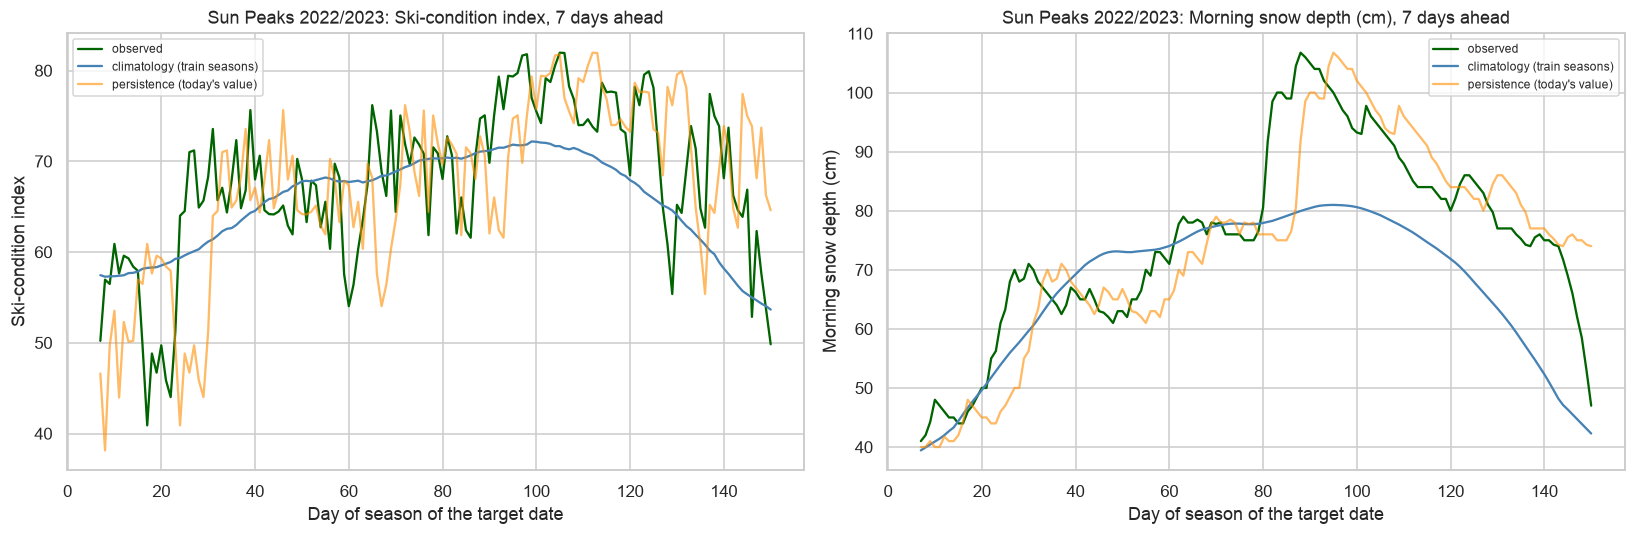

In [167]:
# Let's see what the two baselines look like against one validation winter
name, s = "Sun Peaks", 2023
v = va[(va["resort"] == name) & (va["season"] == s)]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, target, lab in zip(axes, [Y_INDEX, Y_DEPTH], ["Ski-condition index", "Morning snow depth (cm)"]):
    ax.plot(v["y_dos"], v[target], color="darkgreen", label="observed")
    ax.plot(v["y_dos"], climatology_predict(tr, v, target), color="steelblue", label="climatology (train seasons)")
    ax.plot(v["y_dos"], persistence_predict(v, target), color="darkorange", alpha=0.6, label="persistence (today's value)")
    ax.set_title(f"{name} {s-1}/{s}: {lab}, {HORIZON} days ahead")
    ax.set_xlabel("Day of season of the target date")
    ax.set_ylabel(lab)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** At Sun Peaks in 2022–23, climatology captures the broad seasonal pattern of the ski index but smooths over sharp daily changes. For morning snow depth, persistence follows the observed rise and decline more closely, though it lags sudden changes by seven days.

# 5. Pipeline: training, validation, and evaluation

1. **Prepare inputs.** Use FEATURES and the seven-day targets from Section 3. Day `t` inputs are assumed to be available when the forecast is issued, after the full day's weather records are available.

2. **Train and validate.** Use the season splits from Section 1. Fit the model and any preprocessing, such as standardization for Ridge, on training rows only. For tuning, use training-season cross-validation and fit preprocessing within each fold. Ridge and Random Forest tuning settings are to be decided (***not sure to keep this sentence***).

3. **Compare forecasts.** Use the same validation rows for each model and the Section 4 reference forecasts. Report MAE and RMSE. In cross-validation, compute the historical average from each fold's training seasons.

4. **Evaluate on held-out winters.** Once the model and settings are fixed, refit the model and preprocessing on the combined training and validation seasons. Recompute the historical average from those seasons and evaluate on the held-out test winters using the same metrics.

   

In [177]:
def fit_and_evaluate(model, train, validation, target):
    
    """Fit a fresh estimator and score it against training-only climatology."""
    fitted_model = clone(model)
    fitted_model.fit(train[FEATURES], train[target])
    
    predictions = fitted_model.predict(validation[FEATURES])
    climatology = climatology_predict(train, validation, target)
    scores = metrics(validation[target], predictions, y_clim=climatology)
    
    return fitted_model, predictions, scores

# 6. Initial models

Every model in this section is fitted on the **training seasons (2006-2020)** and scored on the **validation seasons (2021-2023)**. The test seasons are not used. Separate models are fitted for the two targets: the index on t+7 and morning snow depth on t+7.

**How settings are chosen:** hyperparameters are tuned by **grouped cross-validation** on the training seasons only (`GroupKFold`, 5 folds, whole seasons held out together), scored by MAE. The validation seasons are used only to compare the frozen models. Grouped CV holds out whole seasons but is not a strictly chronological backtest (a fold can train on winters later than the ones it predicts), so the fixed train → validation split gives the forward-in-time comparison. The MS2 slides mention "expanding-window validation"; MS3 uses grouped-by-season CV instead.

**How models are scored:** every table reports MAE, RMSE and R² on the validation seasons, plus **skill vs climatology** = 1 − model MAE / climatology MAE (the `skill` column from the Section 4 `metrics()` helper). Skill above 0 means the model beats climatology, 0 means a tie, and below 0 means it is worse. **Improvement vs primary** uses the same formula with the stronger baseline for each target: climatology for the index, persistence for depth.

## 6.0 Hyperparameters, fixed before any validation scoring

All Section 6 settings are set in the next cell and are not changed after looking at validation results. Values inherited from Sections 1-5 are listed in the comment block and used as they are.

In [178]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

# Inherited from Sections 1-5 (used as is, not retuned here)
#   HORIZON = 7          forecast lead time in days (Section 1, proposal)
#   CLIM_SMOOTH = 7      3.2 LOSO: best for the index (MAE 6.086); depth was best at +-10 (22.829 vs 22.830), +-7 is used for both
#   LAGS, WINDOWS        3.2 LOSO with Ridge alpha=10 (a fixed screening choice, not tuned); all 77 FEATURES kept
#                        (MAE 5.380 for all 77; the long-window subset scored 5.375)
#   days_since_snow10    threshold 10 cm, cap 60 days (every tested setting gave about 5.380)
#   KNN_GRID             3.2 LOSO: best k = 100 for the index, 25 for depth; k = 400 dropped
#   TREE_LEAF = 20       3.2 LOSO, index target only, at max_depth=6: leaf 50 scored best (5.544) vs 20 (5.556);
#                        the constant is 20 and is used as is (see 6.2)
#   SEED = 2026

CV = GroupKFold(n_splits=5)                # HP: CV folds, whole training seasons held out (3 per fold) | source: new in Section 6, set before validation | MS4: no
RIDGE_ALPHAS = np.logspace(-2, 3, 11)      # HP: Ridge penalty grid, includes the alpha=10 used in 3.2 | source: new in Section 6, set before validation | MS4: no
LASSO_ALPHAS = np.logspace(-3, 1, 9)       # HP: Lasso penalty grid, wide enough for index points and cm | source: new in Section 6, set before validation | MS4: no
LASSO_MAX_ITER = 50_000                    # HP: Lasso solver iterations, set high so it converges | source: new in Section 6, set before validation | MS4: no
TREE_DEPTHS = [4, 6, 8, 10, 12]            # HP: decision-tree max_depth grid, includes the depth 6 used in 3.2 | source: new in Section 6, set before validation | MS4: no
RF_PARAMS = dict(n_estimators=300, max_features=1/3, min_samples_leaf=5, n_jobs=-1)   # HP: random forest, J/3 predictors per split (L21), preliminary | source: new in Section 6, set before validation | MS4: yes
GB_PARAMS = dict(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8)    # HP: gradient boosting, small standard settings, preliminary | source: new in Section 6, set before validation | MS4: yes
PERM_REPEATS = 10                          # HP: permutation-importance repeats | source: new in Section 6, set before validation | MS4: no
S6 = "s6_v1"                               # cache version for Section 6 results; change it if any setting above changes

In [179]:
# Explicit training and validation rows (the test seasons are never selected here)
train_df = sup[sup["season"].isin(TRAIN_SEASONS)].reset_index(drop=True)
val_df = sup[sup["season"].isin(VAL_SEASONS)].reset_index(drop=True)
TARGETS6 = [Y_INDEX, Y_DEPTH]
LABEL = {Y_INDEX: "index", Y_DEPTH: "depth"}
UNIT = {Y_INDEX: "index points", Y_DEPTH: "cm"}
PRIMARY = {Y_INDEX: "climatology", Y_DEPTH: "persistence"}   # the stronger baseline for each target (Section 4)

# Baseline predictions on the exact validation rows, in val_df order
BASE = {t: {"climatology": climatology_predict(train_df, val_df, t), "persistence": persistence_predict(val_df, t)} for t in TARGETS6}

# Data check: the recomputed baselines must match the Section 4 table
for t, ref in [(Y_INDEX, {"climatology": 5.729, "persistence": 7.104}), (Y_DEPTH, {"climatology": 18.213, "persistence": 10.402})]:
    for b, r in ref.items():
        mae = mean_absolute_error(val_df[t], BASE[t][b])
        assert abs(mae - r) < 0.01, f"{LABEL[t]} {b} MAE {mae:.3f} differs from {r}: the local data differ"
print(f"Training rows: {len(train_df):,} ({train_df['season'].nunique()} seasons) | validation rows: {len(val_df):,} ({val_df['season'].nunique()} seasons)")
print("Data check passed: recomputed baseline MAEs match Section 4.")

Training rows: 15,148 (15 seasons) | validation rows: 3,024 (3 seasons)
Data check passed: recomputed baseline MAEs match Section 4.


In [180]:
# Section 6 helpers
def grouped_cv(name, estimator, grid, target):
    """Grouped CV on the training seasons only (same folds for every model).
    Returns the selected (unfitted) estimator, its parameters and its training-CV MAE. The CV table is cached."""
    def run():
        gs = GridSearchCV(estimator, grid, cv=CV, scoring="neg_mean_absolute_error", n_jobs=-1)
        gs.fit(train_df[FEATURES], train_df[target], groups=train_df["season"])
        out = pd.DataFrame(gs.cv_results_["params"], index=range(len(gs.cv_results_["params"])))
        out["cv_MAE"], out["cv_MAE_sd"] = -gs.cv_results_["mean_test_score"], gs.cv_results_["std_test_score"]
        return out
    res = cached(f"{S6}_cv_{name}_{LABEL[target]}", run)
    best = res.loc[res["cv_MAE"].idxmin()]
    params = {k: (int(best[k]) if isinstance(v[0], (int, np.integer)) else float(best[k])) for k, v in grid.items()}
    return clone(estimator).set_params(**params), params, best["cv_MAE"], best["cv_MAE_sd"]

def select(name, estimator, grid, target, show):
    est, params, cv_mae, cv_sd = grouped_cv(name, estimator, grid, target)
    SELECTED[target][name] = est
    CV_SUMMARY[(LABEL[target], name)] = {"selected setting": show(params), "train-CV MAE": cv_mae, "train-CV MAE sd": cv_sd}

def cv_table(models):
    """Training-CV summary for the given models, index first (re-running a cell overwrites, never duplicates)."""
    keys = [(LABEL[t], m) for t in TARGETS6 for m in models]
    return pd.DataFrame([CV_SUMMARY[k] for k in keys], index=pd.MultiIndex.from_tuples(keys, names=["target", "model"]))

def validate(target):
    """Fit every frozen model on the training rows with fit_and_evaluate and keep its validation predictions (cached)."""
    def run():
        out = val_df[["resort", "date", "y_date"]].copy()
        for name, est in SELECTED[target].items():
            _, out[name], _ = fit_and_evaluate(est, train_df, val_df, target)
        return out
    preds = cached(f"{S6}_valpred_{LABEL[target]}", run)
    assert (preds["resort"].values == val_df["resort"].values).all(), "cached rows misaligned"
    assert (pd.to_datetime(preds["date"]).values == val_df["date"].values).all(), "cached rows misaligned"
    return preds

def score_row(model, target, yhat):
    """Validation metrics; skill is vs climatology (helper definition), improvement is vs the primary baseline."""
    m = metrics(val_df[target], yhat, BASE[target]["climatology"])
    prim = mean_absolute_error(val_df[target], BASE[target][PRIMARY[target]])
    return {"model": model, "target": LABEL[target], **m, "improvement vs primary": 1 - m["MAE"] / prim}

SELECTED = {t: {} for t in TARGETS6}   # selected, unfitted estimators per target
CV_SUMMARY = {}                        # training-CV results per (target, model), kept apart from validation results

## 6.1 Baseline model (Ridge) and why

**Why Ridge first.** Ridge is linear regression with an L2 penalty. It is simple and fast, and the penalty keeps the 77 strongly correlated features (lags, rolling windows, current-day values) from giving unstable coefficients. It is the **learned reference model** that the other course methods are compared with. This is different from the two **forecast baselines** of Section 4 (climatology and persistence), which are not fitted on the features.

Plain **LinearRegression** (scaled, no penalty) is shown next to it as an unregularized reference. Its coefficients are not interpreted: the 7 resort indicators always sum to 1 and `region_east` is the sum of the two east-resort indicators, so the unpenalized coefficients are not unique (its predictions are still valid). Ridge coefficients are read in 6.6 as fitted associations, with caution because many features are correlated.

In [181]:
for t in TARGETS6:
    select("LinearRegression", make_pipeline(StandardScaler(), LinearRegression()), {}, t, lambda p: "none")
    select("Ridge", make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": list(RIDGE_ALPHAS)}, t, lambda p: f"alpha = {p['ridge__alpha']:g}")

print("Training-CV results (grouped by season, training seasons only; not validation scores):")
cv_table(["LinearRegression", "Ridge"]).round(3)

Training-CV results (grouped by season, training seasons only; not validation scores):


selected setting  train-CV MAE  train-CV MAE sd
target model                                                           
index  LinearRegression             none         5.384            0.149
       Ridge                  alpha = 10         5.379            0.142
depth  LinearRegression             none         9.341            0.171
       Ridge                 alpha = 100         9.333            0.162

In [182]:
rows = []
for t in TARGETS6:
    for name in ["LinearRegression", "Ridge"]:
        _, yhat, _ = fit_and_evaluate(SELECTED[t][name], train_df, val_df, t)
        rows.append(score_row(name, t, yhat))
    rows.append(score_row(PRIMARY[t] + " (primary baseline)", t, BASE[t][PRIMARY[t]]))
print("Validation results (2021-2023). MAE and RMSE in index points for the index, cm for depth:")
pd.DataFrame(rows).set_index(["target", "model"]).rename(columns={"skill": "skill vs climatology"}).round(3)

Validation results (2021-2023). MAE and RMSE in index points for the index, cm for depth:


MAE    RMSE     R2  skill vs climatology  improvement vs primary
target model                                                                                              
index  LinearRegression                 5.296   6.811  0.645                 0.075                   0.075
       Ridge                            5.299   6.808  0.645                 0.075                   0.075
       climatology (primary baseline)   5.729   7.683  0.548                 0.000                   0.000
depth  LinearRegression                 8.661  12.123  0.983                 0.524                   0.167
       Ridge                            8.679  12.180  0.983                 0.523                   0.166
       persistence (primary baseline)  10.402  15.156  0.973                 0.429                   0.000

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** Grouped CV selected Ridge alpha = 10 for the index and alpha = 100 for depth. On the validation seasons, Ridge reached an index MAE of 5.299, below climatology (5.729; skill vs climatology 0.075), and a depth MAE of 8.679 cm, below persistence (10.402 cm; improvement 0.166). Plain LinearRegression scored almost the same (5.296 and 8.661), so the penalty made little difference here.

## 6.2 Other course methods

The revised proposal names Ridge, Lasso, Random Forest and Gradient Boosting as the planned models. kNN and a single decision tree are added as extra course methods. Lasso, kNN and the tree are tuned by the same grouped CV; **Random Forest and Gradient Boosting use the fixed settings from 6.0 and are preliminary** (their tuning is left for MS4).

**Note on `TREE_LEAF`:** the 3.2 text says a minimum leaf size of 50 scored best (5.544), but the constant is 20 (5.556). The tree below uses `TREE_LEAF` = 20 as it is; the gap between the two was 0.012 index points.

In [183]:
for t in TARGETS6:
    select("Lasso", make_pipeline(StandardScaler(), Lasso(max_iter=LASSO_MAX_ITER, random_state=SEED)), {"lasso__alpha": list(LASSO_ALPHAS)}, t, lambda p: f"alpha = {p['lasso__alpha']:g}")
    select("kNN", make_pipeline(StandardScaler(), KNeighborsRegressor()), {"kneighborsregressor__n_neighbors": KNN_GRID}, t, lambda p: f"k = {p['kneighborsregressor__n_neighbors']}")
    select("DecisionTree", DecisionTreeRegressor(min_samples_leaf=TREE_LEAF, random_state=SEED), {"max_depth": TREE_DEPTHS}, t, lambda p: f"max_depth = {p['max_depth']}, leaf = {TREE_LEAF}")
    select("RandomForest", RandomForestRegressor(**RF_PARAMS, random_state=SEED), {}, t, lambda p: "fixed (preliminary)")
    select("GradientBoosting", GradientBoostingRegressor(**GB_PARAMS, random_state=SEED), {}, t, lambda p: "fixed (preliminary)")

print("Training-CV results (grouped by season, training seasons only; not validation scores):")
cv_table(["Lasso", "kNN", "DecisionTree", "RandomForest", "GradientBoosting"]).round(3)

Training-CV results (grouped by season, training seasons only; not validation scores):


selected setting  train-CV MAE  train-CV MAE sd
target model                                                                    
index  Lasso                         alpha = 0.01         5.378            0.136
       kNN                                 k = 50         5.513            0.107
       DecisionTree      max_depth = 6, leaf = 20         5.634            0.178
       RandomForest           fixed (preliminary)         5.329            0.097
       GradientBoosting       fixed (preliminary)         5.322            0.112
depth  Lasso                          alpha = 0.1         9.272            0.149
       kNN                                 k = 25        15.295            1.008
       DecisionTree      max_depth = 6, leaf = 20        10.922            0.159
       RandomForest           fixed (preliminary)         9.772            0.163
       GradientBoosting       fixed (preliminary)         9.444            0.140

In [184]:
# Fit every frozen model on the training seasons and predict the validation seasons
VALPRED = {t: validate(t) for t in TARGETS6}
MODELS = list(SELECTED[Y_INDEX])
print("Models:", ", ".join(MODELS))

Models: LinearRegression, Ridge, Lasso, kNN, DecisionTree, RandomForest, GradientBoosting


<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** Grouped CV selected Lasso alpha = 0.01 (index) and 0.1 (depth), kNN k = 50 (index) and 25 (depth), and max_depth = 6 for the tree on both targets. In training CV, the preliminary GradientBoosting (5.322) and RandomForest (5.329) had the lowest index MAE, and Lasso had the lowest depth MAE (9.272 cm). For the index, kNN chose k = 50 here rather than the k = 100 found by leave-one-season-out in 3.2; the two schemes hold out seasons differently, and the 3.2 scores for k = 50 and k = 100 were close (5.504 and 5.497).

## 6.3 Results on the validation seasons

One row per model and target, scored on the same validation rows (2021-2023). **Skill vs climatology** = 1 − MAE / climatology MAE (the Section 4 helper). **Improvement vs primary** = 1 − MAE / MAE of the primary baseline, which is climatology for the index and persistence for depth. Positive values mean the model beats that baseline. Models are ranked by validation MAE within each target.

In [185]:
rows = []
for t in TARGETS6:
    rows += [score_row(name, t, VALPRED[t][name]) for name in MODELS]
    rows += [score_row(b, t, BASE[t][b]) for b in ["climatology", "persistence"]]
VAL_TBL = pd.DataFrame(rows).rename(columns={"skill": "skill vs climatology"})
VAL_TBL["unit"] = VAL_TBL["target"].map({"index": "index points", "depth": "cm"})
VAL_TBL = VAL_TBL.sort_values(["target", "MAE"], ascending=[False, True]).set_index(["target", "model"])
BEST = {t: VAL_TBL.loc[LABEL[t]].drop(["climatology", "persistence"])["MAE"].idxmin() for t in TARGETS6}
BEST_TREE = {t: VAL_TBL.loc[LABEL[t]].loc[["DecisionTree", "RandomForest", "GradientBoosting"], "MAE"].idxmin() for t in TARGETS6}
print("Best on validation:", {LABEL[t]: BEST[t] for t in TARGETS6}, "| best tree model on validation:", {LABEL[t]: BEST_TREE[t] for t in TARGETS6})
VAL_TBL.round(3)

Best on validation: {'index': 'RandomForest', 'depth': 'GradientBoosting'} | best tree model on validation: {'index': 'RandomForest', 'depth': 'GradientBoosting'}


MAE    RMSE     R2  skill vs climatology  improvement vs primary          unit
target model                                                                                              
index  RandomForest       5.243   6.756  0.650                 0.085                   0.085  index points
       GradientBoosting   5.267   6.741  0.652                 0.081                   0.081  index points
       LinearRegression   5.296   6.811  0.645                 0.075                   0.075  index points
       Ridge              5.299   6.808  0.645                 0.075                   0.075  index points
       Lasso              5.314   6.811  0.645                 0.072                   0.072  index points
       kNN                5.503   7.171  0.606                 0.039                   0.039  index points
       DecisionTree       5.608   7.211  0.601                 0.021                   0.021  index points
       climatology        5.729   7.683  0.548                 0.000                   0.000  index points
       persistence        7.104   9.225  0.348                -0.240                  -0.240  index points
depth  GradientBoosting   8.647  12.172  0.983                 0.525                   0.169            cm
       Lasso              8.656  12.186  0.983                 0.525                   0.168            cm
       LinearRegression   8.661  12.123  0.983                 0.524                   0.167            cm
       Ridge              8.679  12.180  0.983                 0.523                   0.166            cm
       RandomForest       9.033  12.812  0.981                 0.504                   0.132            cm
       persistence       10.402  15.156  0.973                 0.429                   0.000            cm
       DecisionTree      10.682  15.037  0.974                 0.413                  -0.027            cm
       kNN               13.317  18.398  0.961                 0.269                  -0.280            cm
       climatology       18.213  25.857  0.923                 0.000                  -0.751            cm

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** RandomForest had the lowest index MAE on validation (5.243; skill vs climatology 0.085), and every learned model beat climatology (5.729). For depth, GradientBoosting was lowest (8.647 cm; improvement vs persistence 0.169), with Lasso (8.656), LinearRegression (8.661) and Ridge (8.679) close behind, while DecisionTree (10.682 cm) and kNN (13.317 cm) did worse than persistence (10.402 cm). These are the best models on validation for MS3, not proven best overall.

## 6.4 Results side by side

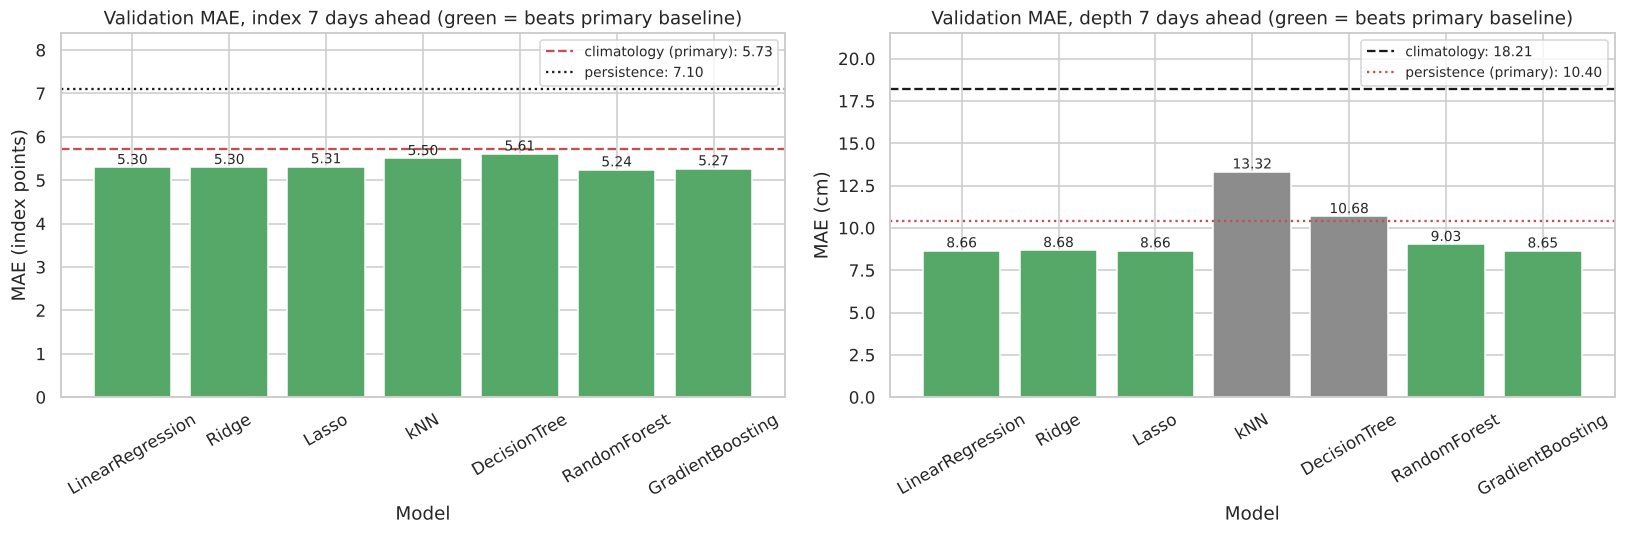

In [186]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, t in zip(axes, TARGETS6):
    r = VAL_TBL.loc[LABEL[t]]
    mae = r.loc[MODELS, "MAE"]
    prim = r.loc[PRIMARY[t], "MAE"]
    ax.bar(MODELS, mae, color=["C2" if v < prim else "C7" for v in mae])
    for b, ls in [("climatology", "--"), ("persistence", ":")]:
        ax.axhline(r.loc[b, "MAE"], color="C3" if b == PRIMARY[t] else "k", ls=ls, lw=1.5,
                   label=f"{b}{' (primary)' if b == PRIMARY[t] else ''}: {r.loc[b, 'MAE']:.2f}")
    for i, v in enumerate(mae):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, 1.18 * max(r.loc[["climatology", "persistence"], "MAE"].max(), mae.max()))
    ax.set_title(f"Validation MAE, {LABEL[t]} 7 days ahead (green = beats primary baseline)")
    ax.set_ylabel(f"MAE ({UNIT[t]})")
    ax.set_xlabel("Model")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** For the index, all seven models sit below the climatology line, but the gaps are small: validation MAE runs from 5.24 (RandomForest) to 5.61 (DecisionTree) against 5.73 for climatology. For depth, five models beat persistence (10.40 cm), while kNN (13.32 cm) and DecisionTree (10.68 cm) do not.

## 6.5 Where the best index model does well and poorly: by resort and by month

For the best index model on validation, the error is broken down by resort and by **target month** (the month of t+7), next to climatology on the same rows. These are descriptive validation diagnostics; they are not used to tune anything.

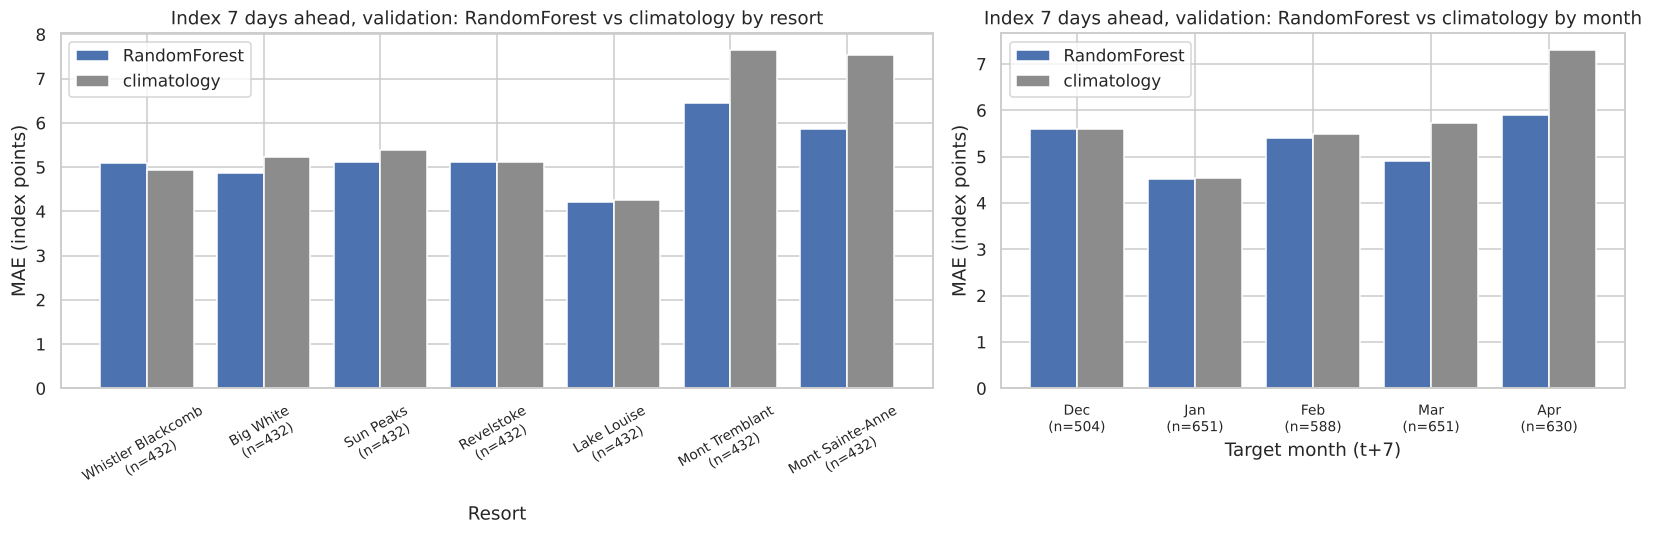

RandomForest, validation MAE (index points); difference = model - climatology (negative = model better)


,n,model_MAE,climatology_MAE,difference
resort,,,,
Whistler Blackcomb,432,5.082,4.936,0.146
Big White,432,4.874,5.223,-0.350
Sun Peaks,432,5.111,5.382,-0.271
Revelstoke,432,5.115,5.125,-0.010
Lake Louise,432,4.218,4.261,-0.043
Mont Tremblant,432,6.452,7.640,-1.188
Mont Sainte-Anne,432,5.851,7.534,-1.683


,n,model_MAE,climatology_MAE,difference
month,,,,
Dec,504,5.603,5.592,0.011
Jan,651,4.511,4.539,-0.028
Feb,588,5.411,5.489,-0.077
Mar,651,4.903,5.727,-0.824
Apr,630,5.906,7.294,-1.387


In [187]:
bm = BEST[Y_INDEX]
err = VALPRED[Y_INDEX][["resort"]].assign(
    month=pd.to_datetime(VALPRED[Y_INDEX]["y_date"]).dt.month,
    model=(val_df[Y_INDEX] - VALPRED[Y_INDEX][bm]).abs().to_numpy(),
    climatology=np.abs(val_df[Y_INDEX].to_numpy() - BASE[Y_INDEX]["climatology"]))
MONTHS = {12: "Dec", 1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr"}

def breakdown(key, order):
    g = err.groupby(key).agg(n=("model", "size"), model_MAE=("model", "mean"), climatology_MAE=("climatology", "mean")).reindex(order)
    g["difference"] = g["model_MAE"] - g["climatology_MAE"]
    return g

by_resort = breakdown("resort", RESORTS)
by_month = breakdown("month", list(MONTHS)).rename(index=MONTHS)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [7, 5]})
for ax, tbl, xl in [(axes[0], by_resort, "Resort"), (axes[1], by_month, "Target month (t+7)")]:
    x = np.arange(len(tbl))
    ax.bar(x - 0.2, tbl["model_MAE"], 0.4, label=bm, color="C0")
    ax.bar(x + 0.2, tbl["climatology_MAE"], 0.4, label="climatology", color="C7")
    ax.set_xticks(x, [f"{i}\n(n={n:,})" for i, n in zip(tbl.index, tbl["n"])], rotation=0 if xl.startswith("Target") else 30, fontsize=9)
    ax.set_xlabel(xl)
    ax.set_ylabel("MAE (index points)")
    ax.legend()
axes[0].set_title(f"Index 7 days ahead, validation: {bm} vs climatology by resort")
axes[1].set_title(f"Index 7 days ahead, validation: {bm} vs climatology by month")
fig.tight_layout()
plt.show()
print(f"{bm}, validation MAE (index points); difference = model - climatology (negative = model better)")
display(by_resort.round(3))
display(by_month.round(3))

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** RandomForest's largest gains over climatology were at the two eastern resorts, Mont Sainte-Anne (−1.683 index points) and Mont Tremblant (−1.188), and in the target months March (−0.824) and April (−1.387). It was slightly worse than climatology at Whistler Blackcomb (+0.146) and about even in December (+0.011). This matches 2.4, where the index's 7-day memory was weakest at Whistler (0.07) and Revelstoke (0.11).

## 6.6 Predicted vs observed, and the drivers

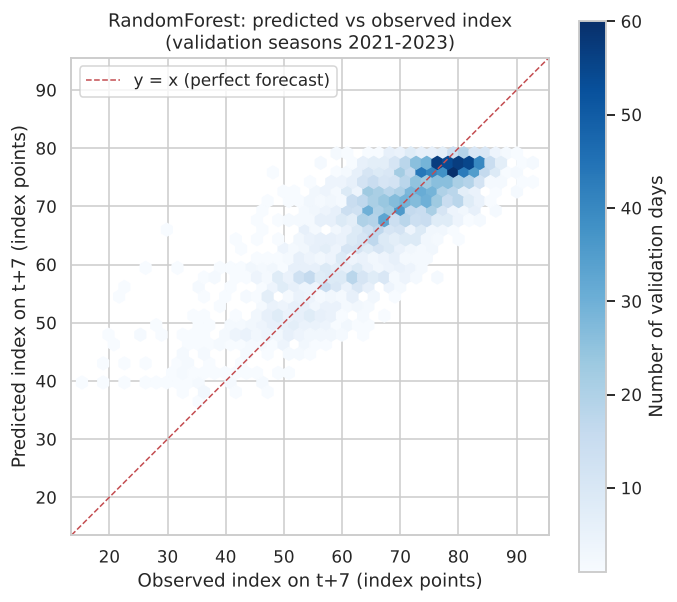

Correlation of predicted and observed: 0.807 | mean predicted 68.27 vs mean observed 68.13


In [188]:
bm = BEST[Y_INDEX]
obs, pred = val_df[Y_INDEX], VALPRED[Y_INDEX][bm]
lim = [min(obs.min(), pred.min()) - 2, max(obs.max(), pred.max()) + 2]
fig, ax = plt.subplots(figsize=(7, 6.5))
hb = ax.hexbin(obs, pred, gridsize=45, cmap="Blues", mincnt=1, extent=lim + lim)
ax.plot(lim, lim, "r--", lw=1, label="y = x (perfect forecast)")
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel("Observed index on t+7 (index points)")
ax.set_ylabel("Predicted index on t+7 (index points)")
ax.set_title(f"{bm}: predicted vs observed index\n(validation seasons 2021-2023)")
fig.colorbar(hb, ax=ax, label="Number of validation days")
ax.legend(loc="upper left")
plt.show()
print(f"Correlation of predicted and observed: {np.corrcoef(obs, pred)[0, 1]:.3f} | mean predicted {pred.mean():.2f} vs mean observed {obs.mean():.2f}")

**Drivers.** Two views, both **predictive associations, not causal effects**:
- **Ridge coefficients** for the index model: the change in predicted index points for a one training-SD increase in a feature, holding the others fixed. Correlated features can split or swap weight between them, so single coefficients are read with caution.
- **Permutation importance** for the best tree-based index model on the validation rows: how much the validation MAE rises when one feature's values are shuffled. Correlated features can share importance (shuffling one leaves its partner intact), which can make each look less important than the group is.

Neither is used to select features or refit models.

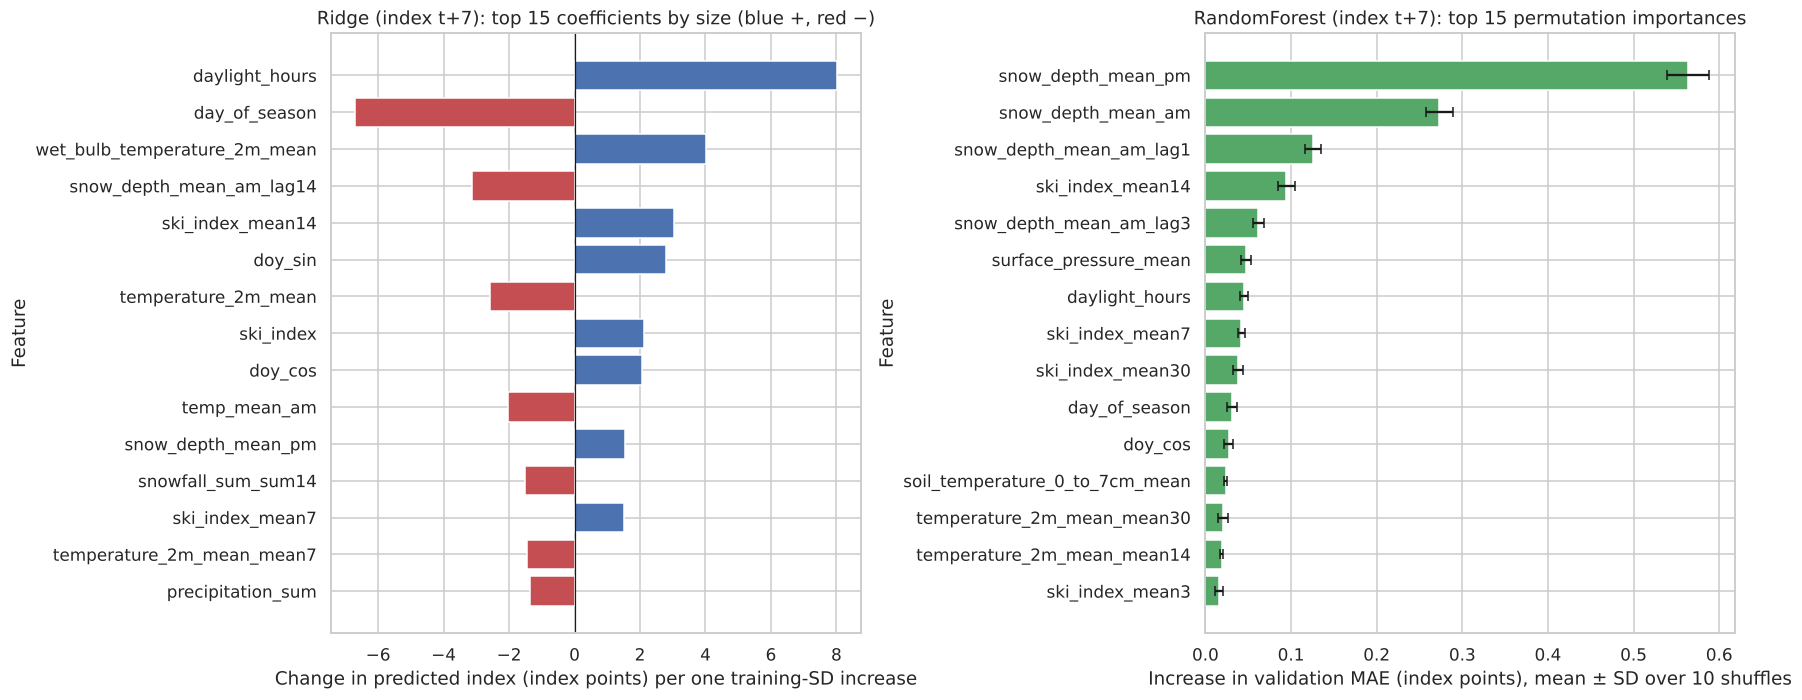

,Ridge coefficient
daylight_hours,8.005
day_of_season,-6.694
wet_bulb_temperature_2m_mean,4.018
snow_depth_mean_am_lag14,-3.130
ski_index_mean14,3.025
doy_sin,2.803
temperature_2m_mean,-2.588
ski_index,2.118
doy_cos,2.060
temp_mean_am,-2.029


,mean,sd
snow_depth_mean_pm,0.564,0.025
snow_depth_mean_am,0.273,0.016
snow_depth_mean_am_lag1,0.126,0.010
ski_index_mean14,0.095,0.010
snow_depth_mean_am_lag3,0.062,0.007
surface_pressure_mean,0.047,0.006
daylight_hours,0.045,0.005
ski_index_mean7,0.042,0.004
ski_index_mean30,0.039,0.006
day_of_season,0.031,0.006


In [189]:
# Ridge coefficients (refit with the selected alpha on the training rows; coefficients are per one training SD)
ridge = clone(SELECTED[Y_INDEX]["Ridge"]).fit(train_df[FEATURES], train_df[Y_INDEX])
coef = pd.Series(ridge[-1].coef_, index=FEATURES)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index[:15])

# Permutation importance of the best tree model on the validation rows (cached)
bt = BEST_TREE[Y_INDEX]
def run_perm():
    model = clone(SELECTED[Y_INDEX][bt]).fit(train_df[FEATURES], train_df[Y_INDEX])
    pi = permutation_importance(model, val_df[FEATURES], val_df[Y_INDEX], scoring="neg_mean_absolute_error",
                                n_repeats=PERM_REPEATS, random_state=SEED, n_jobs=-1)
    return pd.DataFrame({"mean": pi.importances_mean, "sd": pi.importances_std}, index=FEATURES)
perm = cached(f"{S6}_perm_{bt}_index", run_perm)
top_perm = perm.sort_values("mean", ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
axes[0].barh(top_coef.index[::-1], top_coef.values[::-1], color=["C0" if v > 0 else "C3" for v in top_coef.values[::-1]])
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_xlabel("Change in predicted index (index points) per one training-SD increase")
axes[0].set_ylabel("Feature")
axes[0].set_title("Ridge (index t+7): top 15 coefficients by size (blue +, red −)")
axes[1].barh(top_perm.index[::-1], top_perm["mean"][::-1], xerr=top_perm["sd"][::-1], color="C2", capsize=3)
axes[1].set_xlabel(f"Increase in validation MAE (index points), mean ± SD over {PERM_REPEATS} shuffles")
axes[1].set_ylabel("Feature")
axes[1].set_title(f"{bt} (index t+7): top 15 permutation importances")
fig.tight_layout()
plt.show()
display(pd.DataFrame({"Ridge coefficient": top_coef.round(3)}))
display(top_perm.round(3))

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** On validation, predicted and observed index correlate at 0.807 and the means agree (68.27 vs 68.13), but the predictions span a narrower range than the observations, so the lowest and highest index days are pulled toward the middle. Permutation importance for RandomForest is led by today's snow depth (afternoon 0.564 and morning 0.273 index points of extra MAE) and yesterday's morning depth (0.126). Ridge's largest coefficients are calendar terms (daylight_hours +8.005, day_of_season −6.694) that are strongly correlated with each other, so their individual sizes should not be read on their own.

## 6.7 One variant: predict the deviation from climatology

Instead of the raw target, the model predicts the **deviation from climatology** (target − climatology), and climatology is added back afterwards. The model then only has to learn how this winter differs from a normal one.

To avoid leakage, each training row's climatology is computed from the **other 14 training seasons** (leave-one-season-out), so a row never sees its own season in its baseline. Validation climatology uses all 15 training seasons, as in Section 4. The settings selected in 6.1-6.2 are frozen and not retuned. The variant is run for Ridge and for each target's best tree model. That tree model was picked on validation and is scored on validation again here, so its comparison carries a mild selection effect. All scores are on the original scale (index points, cm), not the deviation scale.

In [190]:
def loso_climatology(df, target):
    """Climatology for each training row, computed from the other training seasons only."""
    out = np.full(len(df), np.nan)
    for s in TRAIN_SEASONS:
        m = (df["season"] == s).to_numpy()
        out[m] = climatology_predict(df[~m], df[m], target)
    assert not np.isnan(out).any()
    return out

def deviation_model(est, target):
    """Fit est on training deviations from out-of-season climatology; return original-scale validation predictions."""
    resid = train_df[target].to_numpy() - loso_climatology(train_df, target)
    model = clone(est).fit(train_df[FEATURES], resid)
    return model.predict(val_df[FEATURES]) + BASE[target]["climatology"]

rows = []
for t in TARGETS6:
    def run(t=t):
        out = val_df[["resort", "date"]].copy()
        for name in dict.fromkeys(["Ridge", BEST_TREE[t]]):
            out[name] = deviation_model(SELECTED[t][name], t)
        return out
    dev_pred = cached(f"{S6}_devpred_{LABEL[t]}", run)
    assert (dev_pred["resort"].values == val_df["resort"].values).all()
    for name in dev_pred.columns[2:]:
        direct = VAL_TBL.loc[(LABEL[t], name)]
        r = score_row(f"{name} (deviation)", t, dev_pred[name])
        r["direct MAE"], r["change in MAE"] = direct["MAE"], r["MAE"] - direct["MAE"]
        rows.append(r)
VARIANT = pd.DataFrame(rows).rename(columns={"skill": "skill vs climatology"}).set_index(["target", "model"])
print("Validation results, original scale. change in MAE = deviation model − direct model (negative = deviation model better)")
VARIANT.round(3)

Validation results, original scale. change in MAE = deviation model − direct model (negative = deviation model better)


MAE    RMSE     R2  skill vs climatology  improvement vs primary  direct MAE  change in MAE
target model                                                                                                                       
index  Ridge (deviation)              5.288   6.856  0.640                 0.077                   0.077       5.299         -0.010
       RandomForest (deviation)       5.303   6.882  0.637                 0.074                   0.074       5.243          0.059
depth  Ridge (deviation)             11.011  15.647  0.972                 0.395                  -0.059       8.679          2.332
       GradientBoosting (deviation)  11.329  15.551  0.972                 0.378                  -0.089       8.647          2.682

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** For the index, predicting the deviation changed little: Ridge improved by 0.010 (5.288 vs 5.299) and RandomForest got worse by 0.059 (5.303 vs 5.243). For depth the variant was clearly worse: Ridge (11.011 cm) and GradientBoosting (11.329 cm) both fell behind persistence (10.402 cm) and their direct versions (8.679 and 8.647 cm). One possible reason, not tested here, is that the depth deviation depends on climatology itself, which is not among the features; the direct models stay the reference for MS4.

### Section 6 summary

**Best direct models on validation (2021-2023):**
- **Index:** RandomForest (preliminary settings), MAE 5.243 index points; skill vs climatology 0.085, which is also the improvement vs the primary baseline (climatology, 5.729).
- **Snow depth:** GradientBoosting (preliminary settings), MAE 8.647 cm; skill vs climatology 0.525 and improvement vs the primary baseline (persistence, 10.402 cm) 0.169.

**Deviation-from-climatology variant (6.7):** it did not beat the best direct model for either target. It gave a small gain for Ridge on the index (−0.010) and was clearly worse for depth (+2.332 cm for Ridge, +2.682 cm for GradientBoosting).

**Points for Section 7 and MS4:**
- The gains over climatology for the index are modest, and the top models are close: the five best index models fall between 5.243 and 5.314, and the four best depth models between 8.647 and 8.679 cm. With only three validation seasons, the ranking among them is not firm.
- The index model helps most at the eastern resorts and in March and April, and not at Whistler Blackcomb or in December (6.5).
- Predictions are pulled toward the middle of the index range (6.6), so the poorest and best ski days are the hardest to forecast.
- RandomForest and GradientBoosting used fixed preliminary settings (marked "MS4: yes" in 6.0) and still came out on top, so tuning them is the first MS4 step. The `TREE_LEAF` mismatch from 3.2 (20 used, 50 reported best) is still open.
- The test seasons 2024-2026 are warmer with thinner snow than the development seasons (MS2), so validation scores may not carry over unchanged.

# 7. What we learned and plan for Milestone 4

This section looks back at the EDA (Section 2) and the initial models (Section 6), and sets out the steps for MS4. Every number here comes from an output above. The test seasons (2024-2026) have still not been used.

## 7.1 Did the EDA change the question?

**Not the question itself.** We still predict the ski index 7 days ahead and compare it with the historical day-of-season average. The EDA changed **how we measure and read the results**:

- **One baseline per resort.** Average index levels differ a lot, from 56.5 at Mont Tremblant to 77.2 at Whistler Blackcomb (2.1), so climatology is computed separately for each resort.
- **More room beyond the calendar for the index than for depth.** The calendar alone explains 56% of the index variation but 90% of the snow-depth variation (2.2).
- **Snow depth as a second target.** The index is a quantity we built, and snow depth carries the largest share of its variance (53.6%), followed by temperature (25.4%) (2.3). Depth is a physical quantity that does not depend on our weights, so it is a useful check outside our own design.
- **A different primary baseline for each target.** After removing the seasonal pattern, the 7-day correlation stays high for snow depth (0.87-0.91) but is weak for the index (0.07-0.45) (2.4). So **persistence** is the bar for depth and **climatology** is the bar for the index, as the Section 4 validation scores confirm (depth: persistence 10.402 vs climatology 18.213 cm; index: climatology 5.729 vs persistence 7.104).

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**In short:** the 7-day signal sits mostly in the **snowpack**, while the day-to-day weather has little 7-day memory. This is why we score every model against two baselines and report the index and depth separately.

## 7.2 What the initial models showed

- **Index:** every learned model beat climatology on validation. The best, RandomForest, reached an MAE of 5.243 against 5.729 for climatology (skill vs climatology 0.085). The gain is real but **modest**.
- **Depth:** GradientBoosting was best at 8.647 cm against 10.402 cm for persistence (improvement 0.169). DecisionTree (10.682 cm) and kNN (13.317 cm) did worse than persistence.
- **The top models are close.** The five best index models fall between 5.243 and 5.314, and the four best depth models between 8.647 and 8.679 cm. With only three validation seasons, the ranking among them is **not firm**.
- **Where the gains are.** The largest MAE reductions over climatology (in index points) are at the eastern resorts, Mont Sainte-Anne (−1.683) and Mont Tremblant (−1.188), and in March (−0.824) and April (−1.387). At Whistler Blackcomb the model is slightly worse (+0.146), and December is about even (+0.011) (6.5).
- **What drives the predictions.** Today's snow depth leads the permutation importance (shuffling it raises the MAE by 0.564 index points for the afternoon value and 0.273 for the morning value) (6.6).
- **Predicting the deviation from climatology** did not beat the direct models for either target (6.7).

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**In short:** learned models add a **modest** gain over climatology for the index and a **clear** gain over persistence for depth. The gains are uneven across resorts and months, so MS4 should report them by group, not only as one overall number.

## 7.3 Limitations to keep in mind

- **Few validation seasons.** Three winters (2021-2023) are a small sample, so small MAE differences between models may not hold.
- **Preliminary settings.** RandomForest and GradientBoosting used fixed settings (marked "MS4: yes" in 6.0) and were not tuned.
- **Extremes are pulled toward the middle.** Predicted and observed index correlate at 0.807, but the predictions span a narrower range than the observations: the worst ski days are predicted too high and the best too low (6.6).
- **The index weights are our design choice.** Results could change with different weights.
- **Climate drift.** The test seasons are warmer than the development seasons at every resort and have thinner snow at most of them (MS2), so validation scores may not carry over unchanged.

## 7.4 Plan for Milestone 4, step by step

1. **Step 1: Tune the tree ensembles.** Tune RandomForest and GradientBoosting with the same grouped-by-season CV on the training seasons only.
2. **Step 2: Check the index weights.** Rebuild the index with the alternative weights from the proposal (snow-heavy, sun-heavy, equal) and check whether the model ranking and the gain over climatology still hold.
3. **Step 3: Handle climate drift.** The `season` number is already a feature (Section 3); check whether it captures the warming trend, and test training on only the most recent 10 seasons, both judged by training CV.
4. **Step 4: Report by group.** Report results by resort, by region (west vs east), and for thin vs deep winters, not only as one overall score.
5. **Step 5: Final test.** Freeze the final models, refit them on 2006-2023 (training plus validation), and score the test seasons 2024-2026 **once**, against both baselines.
6. **Step 6 (optional): Longer horizons.** If time allows, repeat the comparison for 14-day and 30-day lead times.